In [1]:
import os, sys, json, hashlib, platform, random
import numpy as np, pandas as pd, sklearn
from google.colab import drive
drive.mount('/content/drive')

PROJECT_DIR = '/content/drive/MyDrive/m4_terraform'
DATA_DIR = f'{PROJECT_DIR}/data'
OUT_DIR  = f'{PROJECT_DIR}/outputs/phase1_validation'
os.makedirs(OUT_DIR, exist_ok=True)

SEED = 42
random.seed(SEED); np.random.seed(SEED)

FILES = {'train': 'aws_train.csv', 'eval': 'aws_eval.csv', 'gold': 'aws_gold.csv'}
for split, fn in FILES.items():
    assert os.path.exists(f'{DATA_DIR}/{fn}'), f'Missing {DATA_DIR}/{fn}'
print('Python', platform.python_version(), '| pandas', pd.__version__,
      '| numpy', np.__version__, '| sklearn', sklearn.__version__)

Mounted at /content/drive
Python 3.13.16 | pandas 2.2.3 | numpy 2.1.3 | sklearn 1.6.1


In [12]:
import csv
csv.field_size_limit(sys.maxsize)
integrity = []
for split, fn in FILES.items():
    p = f'{DATA_DIR}/{fn}'
    raw = open(p, 'rb').read()
    with open(p, newline='', encoding='utf-8') as f:
        rows = list(csv.reader(f))
    header, body = rows[0], rows[1:]
    integrity.append({'split': split, 'bytes': len(raw), 'MiB': round(len(raw)/2**20, 2),
                      'sha256': hashlib.sha256(raw).hexdigest(), 'header': header,
                      'records': len(body),
                      'rows_wrong_width': sum(len(r) != len(header) for r in body)})
integrity_df = pd.DataFrame(integrity)
display(integrity_df.drop(columns='sha256'))
for r in integrity:
    if r['rows_wrong_width']:
        print(f"WARNING {r['split']}: {r['rows_wrong_width']} malformed row(s) - possible truncation")
integrity_df.to_csv(f'{OUT_DIR}/file_integrity.csv', index=False)

,split,bytes,MiB,header,records,rows_wrong_width
0,train,104903766,100.04,"[tf_code, violated_rules]",46160,1
1,eval,13309836,12.69,"[tf_code, violated_rules]",5931,0
2,gold,1682195,1.60,"[tf_code, violated_rules]",1000,0


WARNING train: 1 malformed row(s) - possible truncation


In [4]:
EXPECTED_COLS = ['tf_code', 'violated_rules']
dfs = {}
for split, fn in FILES.items():
    df = pd.read_csv(f'{DATA_DIR}/{fn}', dtype=str, keep_default_na=False, na_values=[])
    assert list(df.columns) == EXPECTED_COLS, f'{split}: unexpected columns {list(df.columns)}'
    df.insert(0, 'row_id', [f'{split}-{i:06d}' for i in range(len(df))])
    df['split'] = split
    dfs[split] = df
    print(f'{split:5s} shape={df.shape}')


train shape=(46160, 4)
eval  shape=(5931, 4)
gold  shape=(1000, 4)


In [5]:
import ast, re
RULE_RE = re.compile(r'^(AVD-AWS-\d{4}|AC_AWS_\d{4})$')

def parse_labels(raw):
    s = raw.strip()
    if s == '':
        return [], 'MISSING'
    try:
        v = ast.literal_eval(s)
    except (ValueError, SyntaxError):
        return [], 'UNPARSEABLE'
    if not isinstance(v, list) or not all(isinstance(x, str) for x in v):
        return [], 'NOT_LIST_OF_STR'
    v = [x.strip() for x in v]
    if any(not RULE_RE.match(x) for x in v):
        return v, 'BAD_RULE_ID'
    if len(v) != len(set(v)):
        return v, 'REPEATED_RULE'
    return v, 'OK'

for split, df in dfs.items():
    parsed = df['violated_rules'].map(parse_labels)
    df['labels'] = parsed.map(lambda t: t[0])
    df['label_status'] = parsed.map(lambda t: t[1])
    df['n_labels'] = df['labels'].map(len)
    print(split, df['label_status'].value_counts().to_dict())

for split, df in dfs.items():
    for _, r in df[df['label_status'] != 'OK'].iterrows():
        print(f"\n{r.row_id} status={r.label_status} chars={len(r.tf_code)}")
        print('  code ends with:', repr(r.tf_code[-120:]))

train {'OK': 46159, 'MISSING': 1}
eval {'OK': 5931}
gold {'OK': 1000}

train-046159 status=MISSING chars=4698
  code ends with: '         = config.name\n      type                        = "LINUX_CONTAINER"\n      compute_type                = "BUILD_'


,train,eval,gold
rows,46160.00,5931.00,1000.00
label_missing_or_bad,1.00,0.00,0.00
empty_code,13.00,11.00,1.00
empty_code_but_has_labels,1.00,1.00,0.00
zero_label_rows,16412.00,2637.00,500.00
positive_rows,29748.00,3294.00,500.00
mean_labels_per_positive_row,3.61,3.78,2.78
max_labels,39.00,33.00,17.00
code_chars_median,1169.00,1132.00,1064.00
code_chars_max,474246.00,70596.00,52824.00


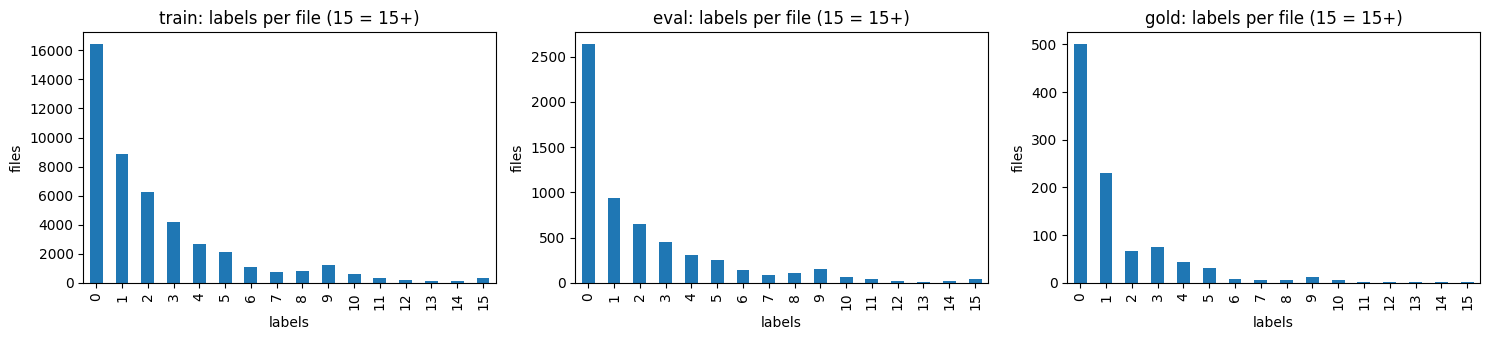

In [6]:
def quality(df):
    empty = df['tf_code'].str.strip() == ''
    return pd.Series({
        'rows': len(df), 'label_missing_or_bad': (df['label_status'] != 'OK').sum(),
        'empty_code': empty.sum(), 'empty_code_but_has_labels': (empty & (df.n_labels > 0)).sum(),
        'zero_label_rows': (df.n_labels == 0).sum(), 'positive_rows': (df.n_labels > 0).sum(),
        'mean_labels_per_positive_row': round(df.loc[df.n_labels > 0, 'n_labels'].mean(), 2),
        'max_labels': df.n_labels.max(),
        'code_chars_median': int(df.tf_code.str.len().median()), 'code_chars_max': df.tf_code.str.len().max()})

quality_df = pd.DataFrame({s: quality(d) for s, d in dfs.items()})
display(quality_df); quality_df.to_csv(f'{OUT_DIR}/quality_summary.csv')

import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for a, (split, df) in zip(ax, dfs.items()):
    df['n_labels'].clip(upper=15).value_counts().sort_index().plot.bar(ax=a)
    a.set_title(f'{split}: labels per file (15 = 15+)'); a.set_xlabel('labels'); a.set_ylabel('files')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/labels_per_file.png', dpi=120); plt.show()

Vocab: 60 {'tfsec/Trivy (AVD)': 46, 'Terrascan (AC)': 14}
In eval not train: []
In gold not train: []
Rules with <10 gold positives: 17


,train,eval,gold,source_scanner,train_prevalence_%,eval_prevalence_%,gold_prevalence_%
AVD-AWS-0104,6948,838,82,tfsec/Trivy (AVD),15.05,14.13,8.2
AVD-AWS-0124,6663,790,79,tfsec/Trivy (AVD),14.43,13.32,7.9
AVD-AWS-0107,5275,633,59,tfsec/Trivy (AVD),11.43,10.67,5.9
AVD-AWS-0028,5073,586,51,tfsec/Trivy (AVD),10.99,9.88,5.1
AVD-AWS-0131,4961,579,51,tfsec/Trivy (AVD),10.75,9.76,5.1
AVD-AWS-0178,4559,517,44,tfsec/Trivy (AVD),9.88,8.72,4.4
AVD-AWS-0057,4431,449,127,tfsec/Trivy (AVD),9.60,7.57,12.7
AVD-AWS-0089,3341,397,34,tfsec/Trivy (AVD),7.24,6.69,3.4
AVD-AWS-0132,3193,392,32,tfsec/Trivy (AVD),6.92,6.61,3.2
AVD-AWS-0099,2776,327,24,tfsec/Trivy (AVD),6.01,5.51,2.4


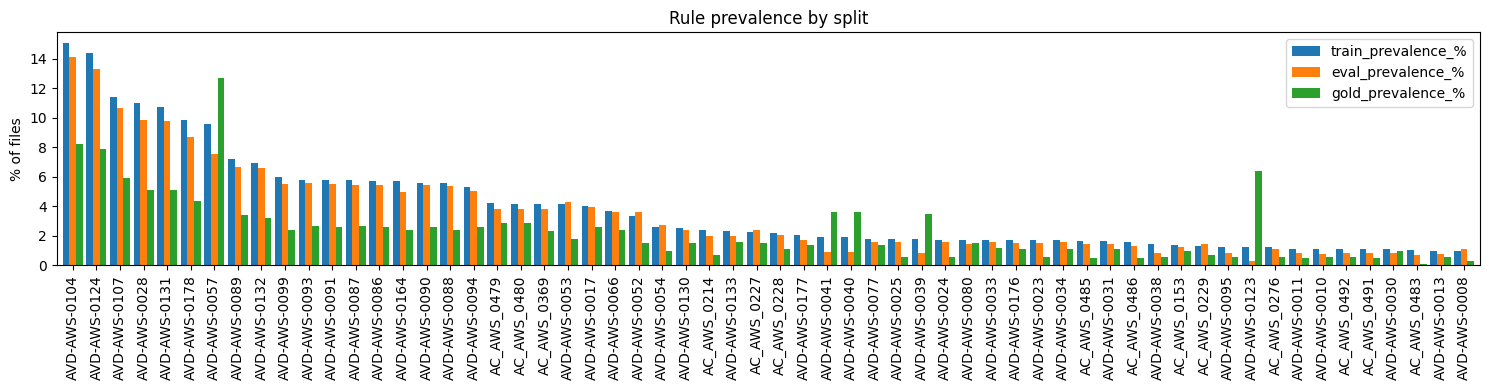

In [7]:
from collections import Counter
counts = {s: Counter(l for ls in d['labels'] for l in ls) for s, d in dfs.items()}
vocab = sorted(set().union(*[set(c) for c in counts.values()]))
freq = pd.DataFrame({s: [counts[s][r] for r in vocab] for s in dfs}, index=vocab)
freq['source_scanner'] = ['tfsec/Trivy (AVD)' if r.startswith('AVD') else 'Terrascan (AC)' for r in vocab]
freq = freq.sort_values('train', ascending=False)
for s in dfs:
    freq[f'{s}_prevalence_%'] = (100 * freq[s] / len(dfs[s])).round(2)
print('Vocab:', len(vocab), freq.source_scanner.value_counts().to_dict())
print('In eval not train:', sorted(set(counts['eval']) - set(counts['train'])))
print('In gold not train:', sorted(set(counts['gold']) - set(counts['train'])))
print('Rules with <10 gold positives:', (freq['gold'] < 10).sum())
display(freq); freq.to_csv(f'{OUT_DIR}/label_frequency.csv')

fig, ax = plt.subplots(figsize=(15, 4))
freq[['train_prevalence_%', 'eval_prevalence_%', 'gold_prevalence_%']].plot.bar(ax=ax, width=0.85)
ax.set_ylabel('% of files'); ax.set_title('Rule prevalence by split')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/label_prevalence.png', dpi=120); plt.show()

In [8]:
def ws_norm(s): return re.sub(r'\s+', ' ', s).strip()
for split, df in dfs.items():
    df['code_hash'] = df.tf_code.map(lambda s: hashlib.sha1(s.encode()).hexdigest())
    df['norm_hash'] = df.tf_code.map(lambda s: hashlib.sha1(ws_norm(s).encode()).hexdigest())
    df['label_key'] = df.labels.map(lambda l: '|'.join(sorted(l)))

display(pd.DataFrame([{'split': s, 'duplicate_code_rows': d.code_hash.duplicated().sum(),
    'unique_codes': d.code_hash.nunique(),
    'codes_with_CONFLICTING_labels': (d.groupby('code_hash').label_key.nunique() > 1).sum()}
    for s, d in dfs.items()]))

overlap = []
for a, b in [('train', 'eval'), ('train', 'gold'), ('eval', 'gold')]:
    for key in ['code_hash', 'norm_hash']:
        shared = set(dfs[a][key]) & set(dfs[b][key])
        hit = dfs[b][key].isin(shared)
        overlap.append({'pair': f'{a} vs {b}', 'match': 'exact' if key == 'code_hash' else 'whitespace-norm',
                        'shared_unique_codes': len(shared), 'rows_in_second': hit.sum(),
                        'pct_of_second': round(100 * hit.mean(), 1)})
overlap_df = pd.DataFrame(overlap); display(overlap_df)
overlap_df.to_csv(f'{OUT_DIR}/cross_split_overlap.csv', index=False)

train_norm, eval_norm = set(dfs['train'].norm_hash), set(dfs['eval'].norm_hash)
dfs['eval']['in_train'] = dfs['eval'].norm_hash.isin(train_norm)
dfs['gold']['in_train'] = dfs['gold'].norm_hash.isin(train_norm)
dfs['gold']['in_eval']  = dfs['gold'].norm_hash.isin(eval_norm)
display(pd.crosstab(dfs['gold'].n_labels > 0, dfs['gold'].in_train,
                    rownames=['gold has labels'], colnames=['also in train']))
tr_lab = dfs['train'].drop_duplicates('norm_hash').set_index('norm_hash').label_key
ov = dfs['gold'][dfs['gold'].in_train]
same = ov.label_key == ov.norm_hash.map(tr_lab)
print(f'Gold rows in train: {len(ov)} | same labels: {same.sum()} | different: {(~same).sum()}')

,split,duplicate_code_rows,unique_codes,codes_with_CONFLICTING_labels
0,train,5150,41010,123
1,eval,242,5689,6
2,gold,303,697,1


,pair,match,shared_unique_codes,rows_in_second,pct_of_second
0,train vs eval,exact,276,338,5.7
1,train vs eval,whitespace-norm,312,394,6.6
2,train vs gold,exact,104,389,38.9
3,train vs gold,whitespace-norm,108,402,40.2
4,eval vs gold,exact,13,22,2.2
5,eval vs gold,whitespace-norm,15,28,2.8


also in train,False,True
gold has labels,,
False,313,187
True,285,215


Gold rows in train: 402 | same labels: 392 | different: 10


In [9]:
!pip -q install datasketch
from datasketch import MinHash, MinHashLSH
def tokens(s): return re.findall(r'[A-Za-z_][A-Za-z0-9_\-\.]*|\d+|[^\sA-Za-z0-9]', s)
def minhash(s, k=5, num_perm=64):
    t = tokens(s); m = MinHash(num_perm=num_perm, seed=SEED)
    for i in range(max(1, len(t) - k + 1)):
        m.update(' '.join(t[i:i+k]).encode())
    return m

THRESH = 0.8
lsh = MinHashLSH(threshold=THRESH, num_perm=64)
tr_u = dfs['train'].drop_duplicates('norm_hash')
for h, code in zip(tr_u.norm_hash, tr_u.tf_code):
    if code.strip(): lsh.insert(h, minhash(code))
for split in ['eval', 'gold']:
    d = dfs[split]
    d['near_dup_train'] = [bool(c.strip()) and len(lsh.query(minhash(c))) > 0 for c in d.tf_code]
    print(f"{split}: exact/ws overlap={d.in_train.sum()} | near-dup>={THRESH}: "
          f"{d.near_dup_train.sum()} ({100*d.near_dup_train.mean():.1f}%)")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.2/107.2 kB 4.1 MB/s eta 0:00:00
eval: exact/ws overlap=394 | near-dup>=0.8: 565 (9.5%)
gold: exact/ws overlap=402 | near-dup>=0.8: 421 (42.1%)


In [10]:
LEAK = {'rule_id_in_code': r'AVD-AWS-\d{4}|AC_AWS_\d{4}', 'tfsec/trivy ignore': r'tfsec:ignore|trivy:ignore',
        'terrascan skip': r'ts:skip', 'checkov skip': r'checkov:skip'}
leak = pd.DataFrame({s: {k: d.tf_code.str.contains(p, regex=True).sum() for k, p in LEAK.items()}
                     for s, d in dfs.items()})
display(leak); leak.to_csv(f'{OUT_DIR}/leakage_token_scan.csv')

,train,eval,gold
rule_id_in_code,27,2,0
tfsec/trivy ignore,266,28,4
terrascan skip,10,1,0
checkov skip,381,22,2


In [11]:
for split, d in dfs.items():
    keep = [c for c in ['row_id', 'split', 'label_status', 'n_labels', 'code_hash', 'norm_hash',
                        'in_train', 'in_eval', 'near_dup_train'] if c in d.columns]
    d[keep].assign(labels=d.labels.map(json.dumps)).to_csv(f'{OUT_DIR}/{split}_flags.csv', index=False)
report = {'seed': SEED, 'files': integrity_df.drop(columns='header').to_dict(orient='records'),
          'quality': quality_df.astype(str).to_dict(), 'label_vocab_size': len(vocab),
          'cross_split_overlap': overlap_df.to_dict(orient='records'), 'leakage_scan': leak.to_dict()}
json.dump(report, open(f'{OUT_DIR}/validation_report.json', 'w'), indent=2, default=str)
print(sorted(os.listdir(OUT_DIR)))


['cross_split_overlap.csv', 'eval_flags.csv', 'file_integrity.csv', 'gold_flags.csv', 'label_frequency.csv', 'label_prevalence.png', 'labels_per_file.png', 'leakage_token_scan.csv', 'quality_summary.csv', 'train_flags.csv', 'validation_report.json']


In [13]:
!git lfs install
!git clone https://github.com/ManassehV2/IaC_Violation_Detection.git /content/repo
!cd /content/repo && git lfs pull
!ls -la /content/repo/dataset/
!sha256sum /content/repo/dataset/*.csv

git: 'lfs' is not a git command. See 'git --help'.

The most similar command is
	log
Cloning into '/content/repo'...
remote: Enumerating objects: 55, done.
remote: Counting objects: 100% (55/55), done.
remote: Compressing objects: 100% (46/46), done.
remote: Total 55 (delta 13), reused 44 (delta 6), pack-reused 0 (from 0)
Receiving objects: 100% (55/55), 80.48 KiB | 5.03 MiB/s, done.
Resolving deltas: 100% (13/13), done.
git: 'lfs' is not a git command. See 'git --help'.

The most similar command is
	log
total 20
drwxr-xr-x 2 root root 4096 Oct 21 05:29 .
drwxr-xr-x 6 root root 4096 Oct 21 05:29 ..
-rw-r--r-- 1 root root  133 Oct 21 05:29 aws_eval.csv
-rw-r--r-- 1 root root  132 Oct 21 05:29 aws_gold.csv
-rw-r--r-- 1 root root  134 Oct 21 05:29 aws_train.csv
9404c5e5dc473b7fb06647450ef5739df1f7b5812d24dd0385e9e5a85a13db98  /content/repo/dataset/aws_eval.csv
5496ab78846d23163aad5330bf791aade92243f7de1937a3b16cbdf9eaa0197d  /content/repo/dataset/aws_gold.csv
a60be93ae511809599990fb828e4e

Y shape (files x rules): (46160, 60)
Rule pairs that appear together in >=80% of cases: 24


,rule_A,rule_B,files_A,files_B,files_both,jaccard
12,AVD-AWS-0086,AVD-AWS-0087,2647,2659,2642,0.992
20,AVD-AWS-0091,AVD-AWS-0093,2668,2686,2662,0.989
13,AVD-AWS-0086,AVD-AWS-0091,2647,2668,2635,0.983
17,AVD-AWS-0087,AVD-AWS-0093,2659,2686,2649,0.983
14,AVD-AWS-0086,AVD-AWS-0093,2647,2686,2640,0.980
16,AVD-AWS-0087,AVD-AWS-0091,2659,2668,2633,0.977
10,AVD-AWS-0040,AVD-AWS-0041,875,883,864,0.966
6,AVD-AWS-0028,AVD-AWS-0131,5073,4961,4891,0.951
0,AC_AWS_0479,AC_AWS_0480,1943,1927,1880,0.945
4,AVD-AWS-0023,AVD-AWS-0025,785,832,781,0.934


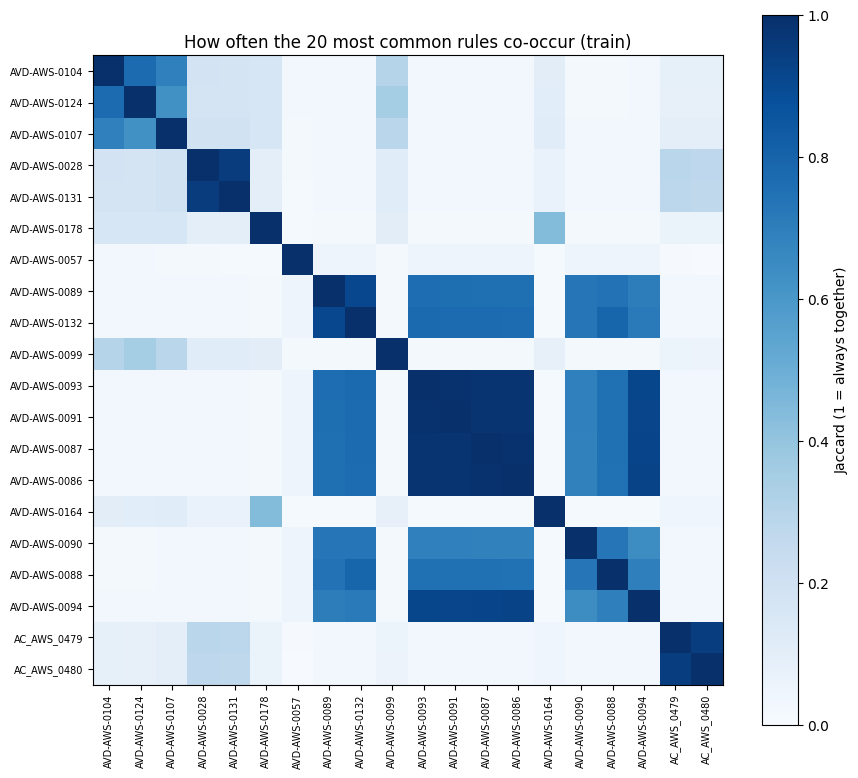

In [14]:
import itertools, matplotlib.pyplot as plt
from sklearn.preprocessing import MultiLabelBinarizer

tr = dfs['train']
mlb = MultiLabelBinarizer()
Y = mlb.fit_transform(tr['labels'])          # rows = files, columns = 60 rules, 1 = rule violated
rules = list(mlb.classes_)
print('Y shape (files x rules):', Y.shape)

n = Y.sum(axis=0)                             # how many files have each rule
both = Y.T @ Y                                # how many files have BOTH rules
pairs = []
for a, b in itertools.combinations(range(len(rules)), 2):
    jac = both[a, b] / (n[a] + n[b] - both[a, b])   # Jaccard: 1.0 = always together
    if jac >= 0.8:
        pairs.append({'rule_A': rules[a], 'rule_B': rules[b], 'files_A': n[a], 'files_B': n[b],
                      'files_both': both[a, b], 'jaccard': round(jac, 3)})
pairs_df = pd.DataFrame(pairs).sort_values('jaccard', ascending=False)
print(f'Rule pairs that appear together in >=80% of cases: {len(pairs_df)}')
display(pairs_df)
pairs_df.to_csv(f'{OUT_DIR}/label_cooccurrence_pairs.csv', index=False)

top = np.argsort(-n)[:20]
J = both[np.ix_(top, top)] / (n[top][:, None] + n[top][None, :] - both[np.ix_(top, top)])
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(J, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(20)); ax.set_xticklabels([rules[i] for i in top], rotation=90, fontsize=7)
ax.set_yticks(range(20)); ax.set_yticklabels([rules[i] for i in top], fontsize=7)
plt.colorbar(im, label='Jaccard (1 = always together)')
ax.set_title('How often the 20 most common rules co-occur (train)')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/label_cooccurrence_heatmap.png', dpi=120); plt.show()


In [15]:
conf = tr.groupby('code_hash')['label_key'].nunique()
conf_hashes = conf[conf > 1].index
ex = tr[tr['code_hash'].isin(conf_hashes)].sort_values('code_hash')
print(f'{len(conf_hashes)} files appear in train with different label sets ({len(ex)} rows). First 3:\n')
for h in conf_hashes[:3]:
    g = ex[ex['code_hash'] == h]
    print('=' * 90)
    print(g['tf_code'].iloc[0][:400], '...\n')
    for _, r in g.iterrows():
        print(f'  {r.row_id}: {r.labels}')

123 files appear in train with different label sets (1577 rows). First 3:

# Autoscaling Notifications
## AWS Bug for SNS Topic: https://stackoverflow.com/questions/62694223/cloudwatch-alarm-pending-confirmation
## Due to that create SNS Topic with unique name 

## SNS - Topic
resource "aws_sns_topic" "myasg_sns_topic" {
  #name = "myasg-sns-topic-${random_pet.this.id}"
  name = "${local.name}-${random_pet.this.id}"
} 

## SNS - Subscription
resource "aws_sns_topic_subsc ...

  train-039035: []
  train-011242: ['AVD-AWS-0095']
  train-007868: ['AVD-AWS-0095']
resource "aws_dynamodb_table" "default-tags-module" {
  name         = "default-tags-module-${var.tablename-suffix}"
  billing_mode = "PAY_PER_REQUEST"
  hash_key     = "KeyId"

  attribute {
    name = "KeyId"
    type = "S"
  }
}
 ...

  train-040050: []
  train-010998: ['AVD-AWS-0024', 'AVD-AWS-0025', 'AVD-AWS-0023']
  train-002348: ['AVD-AWS-0024', 'AVD-AWS-0025', 'AVD-AWS-0023']
resource "aws_ecr_repository" "demo_app_ecr_rep

In [16]:
!apt-get -qq install git-lfs
!cd /content/repo && git lfs install && git lfs pull
!ls -la /content/repo/dataset/
!sha256sum /content/repo/dataset/*.csv

Selecting previously unselected package git-lfs.
(Reading database ... 122807 files and directories currently installed.)
Preparing to unpack .../git-lfs_3.4.1-1ubuntu0.4_amd64.deb ...
Unpacking git-lfs (3.4.1-1ubuntu0.4) ...
Setting up git-lfs (3.4.1-1ubuntu0.4) ...
Processing triggers for man-db (2.12.0-4build2) ...
Updated Git hooks.
Git LFS initialized.
total 117100
drwxr-xr-x 2 root root      4096 Oct 21 05:29 .
drwxr-xr-x 6 root root      4096 Oct 21 05:29 ..
-rw-r--r-- 1 root root  13309836 Oct 21 05:48 aws_eval.csv
-rw-r--r-- 1 root root   1682195 Oct 21 05:48 aws_gold.csv
-rw-r--r-- 1 root root 104903766 Oct 21 05:48 aws_train.csv
2da482bb3d707726269320cfafd12ec1fe8731b6e24014a1bb2ef57603cae313  /content/repo/dataset/aws_eval.csv
8e4170931e213a517d57b935bd214985b1319b0f9ab3e41291073c350cdac321  /content/repo/dataset/aws_gold.csv
ad98f8d2a7496c806b587be13e63cdfcf6ca7c318267528ff790e36428e378ab  /content/repo/dataset/aws_train.csv


In [17]:
from sklearn.preprocessing import MultiLabelBinarizer
train_raw, eval_df = dfs['train'], dfs['eval']
drop_mask = (train_raw['label_status'] != 'OK') | (train_raw['tf_code'].str.strip() == '')
dropped = train_raw.loc[drop_mask, ['row_id', 'label_status']]
train_df = train_raw.loc[~drop_mask].reset_index(drop=True)
print(f'Train rows: {len(train_raw)} -> {len(train_df)} (dropped {drop_mask.sum()}: truncated row + empty-code rows)')
dropped.to_csv(f'{OUT_DIR}/train_rows_excluded.csv', index=False)

mlb = MultiLabelBinarizer()
Y_train = mlb.fit_transform(train_df['labels'])   # learn the 60-rule list from TRAIN only
Y_eval  = mlb.transform(eval_df['labels'])
RULES = list(mlb.classes_)
assert len(RULES) == 60
print('Y_train', Y_train.shape, '| Y_eval', Y_eval.shape)

Train rows: 46160 -> 46146 (dropped 14: truncated row + empty-code rows)
Y_train (46146, 60) | Y_eval (5931, 60)


In [18]:
import time
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack

# Keeps Terraform-meaningful tokens: aws_s3_bucket, kms_key_id, IPs/CIDRs like 0.0.0.0/0, ::/0, and *
TOKEN_PATTERN = r'[A-Za-z_][A-Za-z0-9_\-]*|\d+(?:\.\d+){3}(?:/\d+)?|::/0|\*'
word_vec = TfidfVectorizer(token_pattern=TOKEN_PATTERN, lowercase=True, ngram_range=(1, 2),
                           min_df=3, max_df=0.95, max_features=100_000, sublinear_tf=True, dtype=np.float32)
char_vec = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5),
                           min_df=3, max_df=0.95, max_features=100_000, sublinear_tf=True, dtype=np.float32)

t = time.time()
Xw_train = word_vec.fit_transform(train_df['tf_code']); Xw_eval = word_vec.transform(eval_df['tf_code'])
print(f'word TF-IDF done in {time.time()-t:.0f}s ->', Xw_train.shape)
t = time.time()
Xc_train = char_vec.fit_transform(train_df['tf_code']); Xc_eval = char_vec.transform(eval_df['tf_code'])
print(f'char TF-IDF done in {time.time()-t:.0f}s ->', Xc_train.shape)

X_train = hstack([Xw_train, Xc_train]).tocsr(); X_eval = hstack([Xw_eval, Xc_eval]).tocsr()
X_train.sort_indices(); X_eval.sort_indices()   # tidy internal order (avoids a parallel-training error)
print('X_train', X_train.shape, f'| non-zero: {X_train.nnz:,} ({100*X_train.nnz/np.prod(X_train.shape):.3f}% of cells)')
vocab = set(word_vec.get_feature_names_out())
for tok in ['aws_s3_bucket', '0.0.0.0/0', '*', 'kms_key_id', 'encrypted']:
    print(f'  token {tok!r} in vocabulary: {tok in vocab}')

word TF-IDF done in 43s -> (46146, 100000)
char TF-IDF done in 194s -> (46146, 100000)
X_train (46146, 200000) | non-zero: 62,479,231 (0.677% of cells)
  token 'aws_s3_bucket' in vocabulary: True
  token '0.0.0.0/0' in vocabulary: True
  token '*' in vocabulary: True
  token 'kms_key_id' in vocabulary: True
  token 'encrypted' in vocabulary: True


In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
t = time.time()
lr = OneVsRestClassifier(LogisticRegression(C=4.0, solver='liblinear', max_iter=1000, random_state=SEED), n_jobs=-1)
lr.fit(X_train, Y_train)
print(f'Trained 60 logistic-regression classifiers in {time.time()-t:.0f}s')
P_eval = lr.predict_proba(X_eval)      # probabilities: 5931 files x 60 rules
print(P_eval.shape)



Trained 60 logistic-regression classifiers in 1572s
(5931, 60)


In [20]:
from sklearn.metrics import (precision_recall_fscore_support, accuracy_score,
                             hamming_loss, average_precision_score)
def evaluate(Y_true, Y_pred, P=None, name='model'):
    r = {'model': name}
    for avg in ['micro', 'macro', 'weighted']:
        p, rc, f, _ = precision_recall_fscore_support(Y_true, Y_pred, average=avg, zero_division=0)
        r[f'{avg}_P'], r[f'{avg}_R'], r[f'{avg}_F1'] = round(p, 4), round(rc, 4), round(f, 4)
    r['exact_match_acc'] = round(accuracy_score(Y_true, Y_pred), 4)
    r['hamming_loss'] = round(hamming_loss(Y_true, Y_pred), 4)
    if P is not None:
        r['micro_PR_AUC'] = round(average_precision_score(Y_true, P, average='micro'), 4)
        r['macro_PR_AUC'] = round(average_precision_score(Y_true, P, average='macro'), 4)
    return r

prev = Y_train.mean(axis=0)                          # B0: just guess each rule's training frequency
P_prior = np.tile(prev, (len(Y_eval), 1))
Y_prior = (P_prior >= 0.5).astype(int)
Y_hat = (P_eval >= 0.5).astype(int)                  # E1: threshold 0.5
results = pd.DataFrame([evaluate(Y_eval, Y_prior, P_prior, 'B0 prevalence (no learning)'),
                        evaluate(Y_eval, Y_hat, P_eval, 'E1 TF-IDF + OvR LogReg @0.5')]).set_index('model').T
display(results)

p, rc, f, sup = precision_recall_fscore_support(Y_eval, Y_hat, average=None, zero_division=0)
ap = [average_precision_score(Y_eval[:, j], P_eval[:, j]) for j in range(60)]
per_rule = pd.DataFrame({'rule': RULES, 'support_eval': sup, 'precision': p.round(3), 'recall': rc.round(3),
                         'f1': f.round(3), 'pr_auc': np.round(ap, 3), 'train_count': Y_train.sum(0)}).sort_values('f1')
print('\nWorst 10 rules by F1:'); display(per_rule.head(10))
print('\nBest 5 rules by F1:'); display(per_rule.tail(5))

model,B0 prevalence (no learning),E1 TF-IDF + OvR LogReg @0.5
micro_P,0.0000,0.8783
micro_R,0.0000,0.7981
micro_F1,0.0000,0.8363
macro_P,0.0000,0.8238
macro_R,0.0000,0.7207
macro_F1,0.0000,0.7575
weighted_P,0.0000,0.8607
weighted_R,0.0000,0.7981
weighted_F1,0.0000,0.8221
exact_match_acc,0.4446,0.7444



Worst 10 rules by F1:


,rule,support_eval,precision,recall,f1,pr_auc,train_count
5,AC_AWS_0276,65,0.467,0.108,0.175,0.293,562
0,AC_AWS_0153,73,0.571,0.110,0.184,0.406,627
2,AC_AWS_0227,144,0.475,0.194,0.276,0.468,1036
4,AC_AWS_0229,84,0.750,0.179,0.288,0.432,606
9,AC_AWS_0483,42,0.400,0.238,0.299,0.289,472
3,AC_AWS_0228,121,0.484,0.248,0.328,0.398,1022
1,AC_AWS_0214,117,0.630,0.248,0.356,0.432,1097
10,AC_AWS_0485,85,0.409,0.318,0.358,0.400,775
11,AC_AWS_0486,78,0.429,0.308,0.358,0.393,728
12,AC_AWS_0491,49,0.577,0.306,0.400,0.427,502



Best 5 rules by F1:


,rule,support_eval,precision,recall,f1,pr_auc,train_count
53,AVD-AWS-0131,579,0.923,0.933,0.928,0.943,4961
48,AVD-AWS-0104,838,0.922,0.933,0.928,0.958,6948
22,AVD-AWS-0028,586,0.924,0.940,0.932,0.949,5073
35,AVD-AWS-0066,215,0.927,0.949,0.938,0.968,1712
16,AVD-AWS-0011,49,0.958,0.939,0.948,0.977,525


In [21]:
import joblib
MODEL_DIR = f'{PROJECT_DIR}/models'; os.makedirs(MODEL_DIR, exist_ok=True)
joblib.dump({'word_vec': word_vec, 'char_vec': char_vec, 'model': lr, 'rules': RULES},
            f'{MODEL_DIR}/E1_tfidf_ovr_logreg.joblib', compress=3)
EXP_DIR = f'{PROJECT_DIR}/outputs/experiments'; os.makedirs(EXP_DIR, exist_ok=True)
results.to_csv(f'{EXP_DIR}/E1_eval_metrics.csv'); per_rule.to_csv(f'{EXP_DIR}/E1_eval_per_rule.csv', index=False)
log = {'experiment': 'E1', 'model': 'OvR LogisticRegression(C=4, liblinear)', 'threshold': 0.5,
       'features': 'word 1-2gram (100k) + char_wb 3-5gram (100k), sublinear TF-IDF, min_df=3, max_df=0.95',
       'train_rows': len(train_df), 'eval_rows': len(eval_df), 'seed': SEED,
       'sklearn': sklearn.__version__, 'metrics_eval': results.iloc[:, 1].to_dict()}
json.dump(log, open(f'{EXP_DIR}/E1_log.json', 'w'), indent=2, default=str)
print('Saved model + experiment log:', sorted(os.listdir(EXP_DIR)))

Saved model + experiment log: ['E1_eval_metrics.csv', 'E1_eval_per_rule.csv', 'E1_log.json']


In [22]:
import scipy.sparse as sp
FEAT_DIR = f'{PROJECT_DIR}/features'; os.makedirs(FEAT_DIR, exist_ok=True)
sp.save_npz(f'{FEAT_DIR}/X_train.npz', X_train); sp.save_npz(f'{FEAT_DIR}/X_eval.npz', X_eval)
np.save(f'{FEAT_DIR}/Y_train.npy', Y_train); np.save(f'{FEAT_DIR}/Y_eval.npy', Y_eval)
json.dump(RULES, open(f'{FEAT_DIR}/rules.json', 'w'))
print('Saved:', sorted(os.listdir(FEAT_DIR)))

Saved: ['X_eval.npz', 'X_train.npz', 'Y_eval.npy', 'Y_train.npy', 'rules.json']


In [23]:
from sklearn.svm import LinearSVC
t = time.time()
svm = OneVsRestClassifier(LinearSVC(C=0.5, max_iter=5000, random_state=SEED), n_jobs=-1)
svm.fit(X_train, Y_train)
print(f'Trained 60 linear SVMs in {time.time()-t:.0f}s')
S_eval = svm.decision_function(X_eval)          # raw scores, NOT probabilities
Y_hat_svm = (S_eval > 0).astype(int)            # SVM's natural threshold is 0
print('Score range:', S_eval.min().round(2), 'to', S_eval.max().round(2))

Trained 60 linear SVMs in 269s
Score range: -5.67 to 5.78


In [24]:
results = pd.DataFrame([evaluate(Y_eval, Y_prior, P_prior, 'B0 prevalence'),
                        evaluate(Y_eval, Y_hat, P_eval, 'E1 LogReg @0.5'),
                        evaluate(Y_eval, Y_hat_svm, S_eval, 'E2 LinearSVM @0')]).set_index('model').T
display(results)

p, rc, f, sup = precision_recall_fscore_support(Y_eval, Y_hat_svm, average=None, zero_division=0)
per_rule_svm = pd.DataFrame({'rule': RULES, 'support_eval': sup, 'precision': p.round(3),
                             'recall': rc.round(3), 'f1': f.round(3)}).sort_values('f1')
print('\nE2 worst 10 rules:'); display(per_rule_svm.head(10))

joblib.dump({'model': svm, 'rules': RULES}, f'{MODEL_DIR}/E2_tfidf_ovr_linearsvc.joblib', compress=3)
results.to_csv(f'{EXP_DIR}/E1_E2_eval_metrics.csv'); per_rule_svm.to_csv(f'{EXP_DIR}/E2_eval_per_rule.csv', index=False)
json.dump({'experiment': 'E2', 'model': 'OvR LinearSVC(C=0.5)', 'threshold': 0.0, 'features': 'same as E1',
           'seed': SEED, 'sklearn': sklearn.__version__, 'metrics_eval': results['E2 LinearSVM @0'].to_dict()},
          open(f'{EXP_DIR}/E2_log.json', 'w'), indent=2, default=str)
print('Saved E2.')

model,B0 prevalence,E1 LogReg @0.5,E2 LinearSVM @0
micro_P,0.0000,0.8783,0.8845
micro_R,0.0000,0.7981,0.8198
micro_F1,0.0000,0.8363,0.8509
macro_P,0.0000,0.8238,0.8268
macro_R,0.0000,0.7207,0.7420
macro_F1,0.0000,0.7575,0.7694
weighted_P,0.0000,0.8607,0.8655
weighted_R,0.0000,0.7981,0.8198
weighted_F1,0.0000,0.8221,0.8354
exact_match_acc,0.4446,0.7444,0.7565



E2 worst 10 rules:


,rule,support_eval,precision,recall,f1
5,AC_AWS_0276,65,0.400,0.092,0.150
9,AC_AWS_0483,42,0.316,0.143,0.197
0,AC_AWS_0153,73,0.562,0.123,0.202
4,AC_AWS_0229,84,0.609,0.167,0.262
1,AC_AWS_0214,117,0.625,0.214,0.318
3,AC_AWS_0228,121,0.569,0.240,0.337
2,AC_AWS_0227,144,0.603,0.243,0.347
12,AC_AWS_0491,49,0.650,0.265,0.377
10,AC_AWS_0485,85,0.459,0.329,0.384
6,AC_AWS_0369,226,0.585,0.336,0.427


Saved E2.


In [25]:
N_FOLDS = 5
groups = train_df['norm_hash'].values               # identical code (ignoring spaces) = same group
uniq = np.unique(groups)
rng = np.random.RandomState(SEED)
shuffled = uniq[rng.permutation(len(uniq))]
fold_of_group = {g: i % N_FOLDS for i, g in enumerate(shuffled)}
fold = np.array([fold_of_group[g] for g in groups])
assert pd.Series(fold).groupby(groups).nunique().max() == 1, 'a duplicate group was split across folds!'

summary = pd.DataFrame({'rows': np.bincount(fold),
                        'positive_files': [int((Y_train[fold == k].sum(1) > 0).sum()) for k in range(N_FOLDS)],
                        'rarest_rule_positives': [int(Y_train[fold == k].sum(0).min()) for k in range(N_FOLDS)]})
display(summary)
CV_DIR = f'{PROJECT_DIR}/cv'; os.makedirs(CV_DIR, exist_ok=True)
np.save(f'{CV_DIR}/fold_ids.npy', fold)

,rows,positive_files,rarest_rule_positives
0,9151,5911,38
1,9299,6101,77
2,9359,6030,41
3,9195,5928,74
4,9142,5777,51


In [26]:
from sklearn.base import clone
C_GRID = [0.1, 0.5, 2.0]
texts = train_df['tf_code'].values
for k in range(N_FOLDS):
    ckpt = f'{CV_DIR}/svm_fold{k}.npz'
    if os.path.exists(ckpt):
        print(f'fold {k}: already done, skipping'); continue
    t0 = time.time()
    tr, va = np.where(fold != k)[0], np.where(fold == k)[0]
    wv, cv = clone(word_vec), clone(char_vec)          # fresh, unfitted copies
    Xtr = hstack([wv.fit_transform(texts[tr]), cv.fit_transform(texts[tr])]).tocsr(); Xtr.sort_indices()
    Xva = hstack([wv.transform(texts[va]), cv.transform(texts[va])]).tocsr(); Xva.sort_indices()
    scores = {}
    for C in C_GRID:
        m = OneVsRestClassifier(LinearSVC(C=C, max_iter=5000, random_state=SEED), n_jobs=-1)
        m.fit(Xtr, Y_train[tr])
        scores[f'C_{C}'] = m.decision_function(Xva).astype(np.float32)
    np.savez(ckpt, val_idx=va, **scores)
    print(f'fold {k}: done in {(time.time()-t0)/60:.1f} min')

fold 0: done in 15.5 min
fold 1: done in 15.6 min
fold 2: done in 15.1 min
fold 3: done in 15.2 min
fold 4: done in 15.3 min


In [28]:
oof = {C: np.zeros(Y_train.shape, dtype=np.float32) for C in C_GRID}
fold_rows = []
for k in range(N_FOLDS):
    z = np.load(f'{CV_DIR}/svm_fold{k}.npz')
    va = z['val_idx']
    for C in C_GRID:
        S = z[f'C_{C}']; oof[C][va] = S
        Yt, Yp = Y_train[va], (S > 0).astype(int)
        fold_rows.append({'C': C, 'fold': k,
            'micro_F1': precision_recall_fscore_support(Yt, Yp, average='micro', zero_division=0)[2],
            'macro_F1': precision_recall_fscore_support(Yt, Yp, average='macro', zero_division=0)[2],
            'micro_PR_AUC': average_precision_score(Yt, S, average='micro'),
            'macro_PR_AUC': average_precision_score(Yt, S, average='macro')})
cv_res = pd.DataFrame(fold_rows).groupby('C').agg(['mean', 'std']).drop(columns='fold').round(4)
display(cv_res)

# Selection rule fixed IN ADVANCE: highest mean micro PR-AUC (threshold-free, because thresholds are tuned later)
BEST_C = cv_res[('micro_PR_AUC', 'mean')].idxmax()
print(f'\nSelected C = {BEST_C}')

np.save(f'{CV_DIR}/oof_scores_svm_best.npy', oof[BEST_C])
cv_res.to_csv(f'{EXP_DIR}/CV_svm_C_selection.csv')
json.dump({'experiment': 'CV-tuning', 'model': 'OvR LinearSVC', 'C_grid': C_GRID, 'selected_C': float(BEST_C),
           'selection_metric': 'mean micro PR-AUC over 5 grouped folds (groups = whitespace-normalised code hash)',
           'vectorizers_refit_per_fold': True, 'seed': SEED, 'sklearn': sklearn.__version__},
          open(f'{EXP_DIR}/CV_log.json', 'w'), indent=2)
print('Saved OOF scores + CV log.')

micro_F1         macro_F1         micro_PR_AUC         macro_PR_AUC  \
        mean     std     mean     std         mean     std         mean   
C                                                                         
0.1   0.8339  0.0043   0.7089  0.0038       0.9080  0.0051       0.8258   
0.5   0.8595  0.0031   0.7734  0.0038       0.9170  0.0046       0.8376   
2.0   0.8610  0.0022   0.7899  0.0025       0.9129  0.0042       0.8335   

             
        std  
C            
0.1  0.0086  
0.5  0.0082  
2.0  0.0073


Selected C = 0.5
Saved OOF scores + CV log.


In [29]:
import joblib, scipy.sparse as sp
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_fscore_support, log_loss, brier_score_loss
FEAT_DIR = f'{PROJECT_DIR}/features'; MODEL_DIR = f'{PROJECT_DIR}/models'
CV_DIR = f'{PROJECT_DIR}/cv'; EXP_DIR = f'{PROJECT_DIR}/outputs/experiments'

X_eval = sp.load_npz(f'{FEAT_DIR}/X_eval.npz'); X_eval.sort_indices()
Y_train, Y_eval = np.load(f'{FEAT_DIR}/Y_train.npy'), np.load(f'{FEAT_DIR}/Y_eval.npy')
RULES = json.load(open(f'{FEAT_DIR}/rules.json'))
S_oof  = np.load(f'{CV_DIR}/oof_scores_svm_best.npy')                                   # honest train scores
S_eval = joblib.load(f'{MODEL_DIR}/E2_tfidf_ovr_linearsvc.joblib')['model'].decision_function(X_eval)
P_eval = joblib.load(f'{MODEL_DIR}/E1_tfidf_ovr_logreg.joblib')['model'].predict_proba(X_eval)  # E1 reference
assert S_oof.shape == Y_train.shape and S_eval.shape == Y_eval.shape
print('Loaded. OOF', S_oof.shape, '| eval scores', S_eval.shape)


Loaded. OOF (46146, 60) | eval scores (5931, 60)


In [30]:
from sklearn.isotonic import IsotonicRegression
n_rules = Y_train.shape[1]
glob = LogisticRegression(C=1e6, max_iter=1000).fit(S_oof.reshape(-1, 1), Y_train.ravel())
P_global = glob.predict_proba(S_eval.reshape(-1, 1))[:, 1].reshape(S_eval.shape)

P_platt = np.zeros_like(S_eval, dtype=float); P_iso = np.zeros_like(S_eval, dtype=float)
platt_models, iso_models = [], []
for j in range(n_rules):
    pl = LogisticRegression(C=1e6, max_iter=1000).fit(S_oof[:, [j]], Y_train[:, j])
    P_platt[:, j] = pl.predict_proba(S_eval[:, [j]])[:, 1]; platt_models.append(pl)
    iso = IsotonicRegression(out_of_bounds='clip', y_min=0, y_max=1).fit(S_oof[:, j], Y_train[:, j])
    P_iso[:, j] = iso.predict(S_eval[:, j]); iso_models.append(iso)

pl0 = platt_models[0]
print(f'Example {RULES[0]}: SVM score 0 -> probability {pl0.predict_proba([[0]])[0,1]:.2f}, '
      f'score 1 -> {pl0.predict_proba([[1]])[0,1]:.3f}')

Example AC_AWS_0153: SVM score 0 -> probability 0.68, score 1 -> 0.997


In [31]:
def ece(y, p, n_bins=15, only_confident=False):
    """Expected Calibration Error: average gap between predicted probability and observed rate."""
    y, p = y.ravel(), p.ravel()
    if only_confident:
        keep = p >= 0.05; y, p = y[keep], p[keep]   # skip the ~97% of cells that are 'clearly secure'
    bins = np.minimum((p * n_bins).astype(int), n_bins - 1)
    return sum((bins == b).mean() * abs(p[bins == b].mean() - y[bins == b].mean())
               for b in range(n_bins) if (bins == b).any())

def calib_report(name, P):
    pr = precision_recall_fscore_support(Y_eval, (P >= 0.5).astype(int), average='micro', zero_division=0)
    return {'method': name, 'Brier': round(np.mean((P - Y_eval) ** 2), 5),
            'LogLoss': round(log_loss(Y_eval.ravel(), np.clip(P, 1e-6, 1 - 1e-6).ravel()), 4),
            'ECE_all': round(ece(Y_eval, P), 4), 'ECE_p>=0.05': round(ece(Y_eval, P, only_confident=True), 4),
            'micro_P@0.5': round(pr[0], 4), 'micro_R@0.5': round(pr[1], 4), 'micro_F1@0.5': round(pr[2], 4)}

calib_df = pd.DataFrame([calib_report('E1 LogReg raw probabilities', P_eval),
                         calib_report('SVM + global Platt', P_global),
                         calib_report('SVM + per-rule Platt', P_platt),
                         calib_report('SVM + per-rule isotonic', P_iso)]).set_index('method')
display(calib_df)


,Brier,LogLoss,ECE_all,ECE_p>=0.05,micro_P@0.5,micro_R@0.5,micro_F1@0.5
method,,,,,,,
E1 LogReg raw probabilities,0.00826,0.0305,0.0031,0.0292,0.8783,0.7981,0.8363
SVM + global Platt,0.00776,0.0311,0.0031,0.0403,0.8815,0.8257,0.8527
SVM + per-rule Platt,0.00777,0.0305,0.0027,0.0306,0.8778,0.8276,0.8520
SVM + per-rule isotonic,0.00764,0.0289,0.0014,0.0211,0.8682,0.8453,0.8566


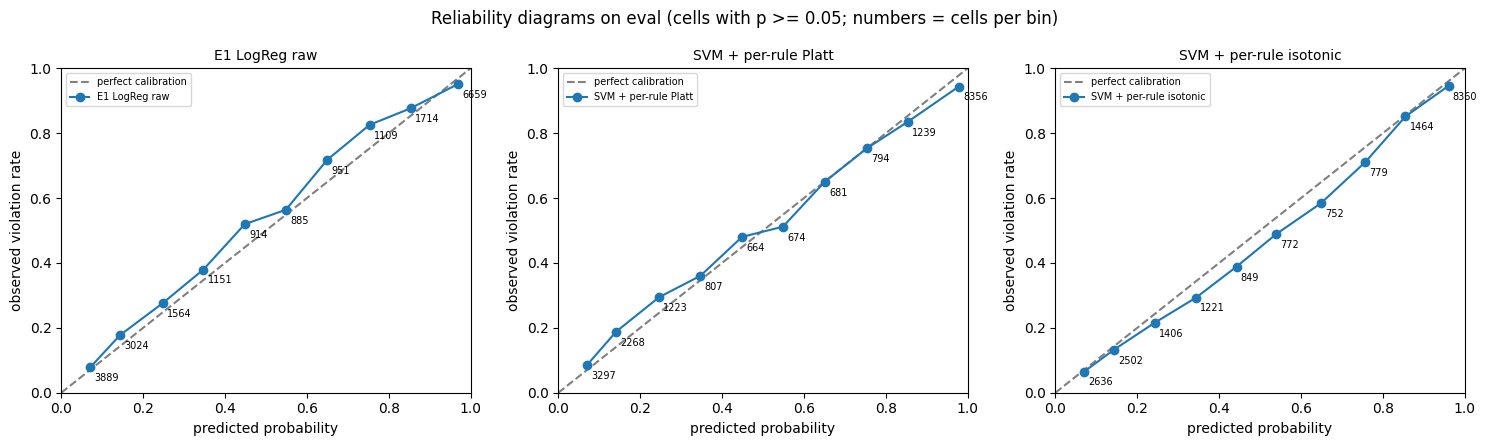

Rules with the WORST calibrated probabilities:


,rule,brier_platt,brier_iso,eval_positives
6,AC_AWS_0369,0.0259,0.0255,226
8,AC_AWS_0480,0.0236,0.0231,228
7,AC_AWS_0479,0.0230,0.0228,227
49,AVD-AWS-0107,0.0201,0.0198,633
47,AVD-AWS-0099,0.0174,0.0177,327
2,AC_AWS_0227,0.0171,0.0164,144
34,AVD-AWS-0057,0.0158,0.0163,449
48,AVD-AWS-0104,0.0157,0.0158,838


In [32]:
import matplotlib.pyplot as plt
def reliability(ax, P, name, n_bins=10):
    y, p = Y_eval.ravel(), P.ravel(); keep = p >= 0.05; y, p = y[keep], p[keep]
    bins = np.minimum((p * n_bins).astype(int), n_bins - 1)
    pts = [(p[bins == b].mean(), y[bins == b].mean(), (bins == b).sum()) for b in range(n_bins) if (bins == b).any()]
    ax.plot([0, 1], [0, 1], '--', color='grey', label='perfect calibration')
    ax.plot([a for a, _, _ in pts], [b for _, b, _ in pts], 'o-', label=name)
    for a, b, n in pts: ax.annotate(str(n), (a, b), fontsize=7, textcoords='offset points', xytext=(3, -10))
    ax.set_xlabel('predicted probability'); ax.set_ylabel('observed violation rate')
    ax.set_title(name, fontsize=10); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.legend(fontsize=7)

cands = [('E1 LogReg raw', P_eval), ('SVM + per-rule Platt', P_platt), ('SVM + per-rule isotonic', P_iso)]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (n, P) in zip(axes, cands): reliability(ax, P, n)
plt.suptitle('Reliability diagrams on eval (cells with p >= 0.05; numbers = cells per bin)')
plt.tight_layout(); plt.savefig(f'{EXP_DIR}/reliability_eval.png', dpi=120); plt.show()

per_rule_cal = pd.DataFrame({'rule': RULES,
    'brier_platt': [round(brier_score_loss(Y_eval[:, j], P_platt[:, j]), 4) for j in range(n_rules)],
    'brier_iso':   [round(brier_score_loss(Y_eval[:, j], P_iso[:, j]), 4) for j in range(n_rules)],
    'eval_positives': Y_eval.sum(0)}).sort_values('brier_platt', ascending=False)
print('Rules with the WORST calibrated probabilities:'); display(per_rule_cal.head(8))

In [33]:
joblib.dump({'global_platt': glob, 'platt': platt_models, 'isotonic': iso_models, 'rules': RULES},
            f'{MODEL_DIR}/calibrators_svm_C0.5.joblib', compress=3)
calib_df.to_csv(f'{EXP_DIR}/E5_calibration_eval.csv'); per_rule_cal.to_csv(f'{EXP_DIR}/E5_per_rule_brier.csv', index=False)
json.dump({'experiment': 'E5 calibration', 'backbone': 'OvR LinearSVC C=0.5', 'fit_on': 'grouped 5-fold OOF train scores',
           'evaluated_on': 'eval (selection set, not final test)', 'methods': ['global Platt', 'per-rule Platt', 'per-rule isotonic'],
           'results': calib_df.to_dict(orient='index')}, open(f'{EXP_DIR}/E5_log.json', 'w'), indent=2)
print('Saved calibrators + E5 log.')

Saved calibrators + E5 log.


In [34]:
import re, hashlib
from sklearn.metrics import precision_recall_curve
if 'P_iso' not in globals():   # rebuild calibrated probabilities after a disconnect
    cal = joblib.load(f'{MODEL_DIR}/calibrators_svm_C0.5.joblib')
    P_iso = np.column_stack([cal['isotonic'][j].predict(S_eval[:, j]) for j in range(60)])
ev = pd.read_csv(f'{DATA_DIR}/aws_eval.csv', dtype=str, keep_default_na=False)
eval_norm_hash = ev['tf_code'].map(lambda s: hashlib.sha1(re.sub(r'\s+', ' ', s).strip().encode()).hexdigest()).values

TARGET_ACT_PRECISION = 0.90   # an automatic ACT must be right at least 90% of the time
TARGET_SAFE_RECALL   = 0.95   # NO ALERT may hide at most 5% of real violations
MIN_POS = 10                  # fewer positives than this -> too little evidence, use fallback

def f1_threshold(y, s):
    p, r, t = precision_recall_curve(y, s)
    f1 = 2 * p[:-1] * r[:-1] / np.maximum(p[:-1] + r[:-1], 1e-12)
    return t[np.argmax(f1)]

def three_way_thresholds(y, s):
    p, r, t = precision_recall_curve(y, s)
    p, r = p[:-1], r[:-1]
    ok_hi = np.where(p >= TARGET_ACT_PRECISION)[0]
    t_high = t[ok_hi].min() if len(ok_hi) else np.inf     # never reliable enough -> never auto-ACT
    ok_lo = np.where(r >= TARGET_SAFE_RECALL)[0]
    t_low = t[ok_lo].max() if len(ok_lo) else t.min()
    return min(t_low, t_high), t_high

def fit_thresholds(Y, S, kind):
    out = []
    for j in range(Y.shape[1]):
        y, s = Y[:, j], S[:, j]
        if y.sum() < MIN_POS:
            out.append((0.5, 0.5) if kind == 'three_way' else 0.5); continue
        out.append(three_way_thresholds(y, s) if kind == 'three_way' else f1_threshold(y, s))
    return np.array(out)

uniq = np.unique(eval_norm_hash); rng = np.random.RandomState(SEED)
gfold = {g: i % 5 for i, g in enumerate(uniq[rng.permutation(len(uniq))])}
efold = np.array([gfold[g] for g in eval_norm_hash])
print('eval folds:', np.bincount(efold).tolist())

def crossfit(S, kind):
    D = np.zeros(S.shape, dtype=int)          # binary 0/1 ; three-way 0=NO ALERT 1=REVIEW 2=ACT
    for k in range(5):
        sel, app = efold != k, efold == k
        th = fit_thresholds(Y_eval[sel], S[sel], kind)
        if kind == 'three_way':
            D[app] = np.where(S[app] >= th[:, 1], 2, np.where(S[app] >= th[:, 0], 1, 0))
        else:
            D[app] = (S[app] >= th).astype(int)
    return D

def crossfit_global(S):
    D = np.zeros(S.shape, dtype=int)
    for k in range(5):
        sel, app = efold != k, efold == k
        D[app] = (S[app] >= f1_threshold(Y_eval[sel].ravel(), S[sel].ravel())).astype(int)
    return D

eval folds: [1176, 1203, 1178, 1192, 1182]


In [35]:
n_files, n_pos = len(Y_eval), Y_eval.sum()
def binary_row(name, D):
    tp = ((D == 1) & (Y_eval == 1)).sum(); fp = ((D == 1) & (Y_eval == 0)).sum(); fn = ((D == 0) & (Y_eval == 1)).sum()
    P, R = tp / max(tp + fp, 1), tp / n_pos
    rule_f1 = [2 * ((D[:, j] == 1) & (Y_eval[:, j] == 1)).sum() / max((D[:, j] == 1).sum() + Y_eval[:, j].sum(), 1) for j in range(60)]
    return {'policy': name, 'auto-alert precision': P, 'recall (caught)': R, 'micro-F1': 2*P*R/(P+R),
            'macro-F1': np.mean(rule_f1), 'false alerts /100 files': 100*fp/n_files,
            'missed /100 files': 100*fn/n_files, 'REVIEW items /100 files': 0.0}

def threeway_row(name, D):
    act, rev, no = D == 2, D == 1, D == 0
    return {'policy': name, 'auto-alert precision': (act & (Y_eval == 1)).sum() / max(act.sum(), 1),
            'recall (caught)': ((act | rev) & (Y_eval == 1)).sum() / n_pos, 'micro-F1': np.nan, 'macro-F1': np.nan,
            'false alerts /100 files': 100 * (act & (Y_eval == 0)).sum() / n_files,
            'missed /100 files': 100 * (no & (Y_eval == 1)).sum() / n_files,
            'REVIEW items /100 files': 100 * rev.sum() / n_files}

D6 = crossfit(P_iso, 'three_way')
policy_df = pd.DataFrame([
    binary_row('E2  SVM, fixed threshold 0', (S_eval > 0).astype(int)),
    binary_row('E3  SVM, one tuned global threshold', crossfit_global(S_eval)),
    binary_row('E4  SVM, per-rule thresholds (no calibration)', crossfit(S_eval, 'binary')),
    binary_row('E5  calibrated, fixed 0.5', (P_iso >= 0.5).astype(int)),
    binary_row('E5b calibrated, per-rule thresholds', crossfit(P_iso, 'binary')),
    threeway_row('E6  calibrated + ACT/REVIEW/NO ALERT', D6)]).set_index('policy').round(3)
display(policy_df)
act_share = (D6 == 2).sum() / max((D6 >= 1).sum(), 1)
print(f'\nE6: {100*act_share:.1f}% of flagged items are automatic ACT, {100*(1-act_share):.1f}% go to REVIEW')

,auto-alert precision,recall (caught),micro-F1,macro-F1,false alerts /100 files,missed /100 files,REVIEW items /100 files
policy,,,,,,,
"E2 SVM, fixed threshold 0",0.885,0.820,0.851,0.769,22.475,37.852,0.000
"E3 SVM, one tuned global threshold",0.857,0.855,0.856,0.790,30.062,30.501,0.000
"E4 SVM, per-rule thresholds (no calibration)",0.816,0.873,0.844,0.802,41.241,26.707,0.000
"E5 calibrated, fixed 0.5",0.868,0.845,0.857,0.781,26.943,32.490,0.000
"E5b calibrated, per-rule thresholds",0.814,0.873,0.843,0.803,41.831,26.606,0.000
E6 calibrated + ACT/REVIEW/NO ALERT,0.902,0.956,NaN,NaN,17.771,9.341,312.005



E6: 36.8% of flagged items are automatic ACT, 63.2% go to REVIEW


In [38]:
sweep = []
for act_p in [0.90, 0.95]:
    for safe_r in [0.80, 0.85, 0.90, 0.95]:
        TARGET_ACT_PRECISION, TARGET_SAFE_RECALL = act_p, safe_r
        r = threeway_row(f'ACT prec {act_p:.2f} | safe recall {safe_r:.2f}', crossfit(P_iso, 'three_way'))
        sweep.append({k: v for k, v in r.items() if k not in ('micro-F1', 'macro-F1')})
TARGET_ACT_PRECISION, TARGET_SAFE_RECALL = 0.90, 0.95
sweep_df = pd.DataFrame(sweep).set_index('policy').round(3)
display(sweep_df)

,auto-alert precision,recall (caught),false alerts /100 files,missed /100 files,REVIEW items /100 files
policy,,,,,
ACT prec 0.90 | safe recall 0.80,0.902,0.891,17.771,22.812,83.359
ACT prec 0.90 | safe recall 0.85,0.902,0.907,17.771,19.491,106.491
ACT prec 0.90 | safe recall 0.90,0.902,0.929,17.771,15.006,156.314
ACT prec 0.90 | safe recall 0.95,0.902,0.956,17.771,9.341,312.005
ACT prec 0.95 | safe recall 0.80,0.942,0.835,5.851,34.632,145.524
ACT prec 0.95 | safe recall 0.85,0.942,0.872,5.851,26.859,174.625
ACT prec 0.95 | safe recall 0.90,0.942,0.910,5.851,18.850,229.455
ACT prec 0.95 | safe recall 0.95,0.942,0.951,5.851,10.302,390.288


In [39]:
CHOSEN = {'act_precision': 0.90, 'safe_recall': 0.85}
TARGET_ACT_PRECISION, TARGET_SAFE_RECALL = CHOSEN['act_precision'], CHOSEN['safe_recall']
th_final = fit_thresholds(Y_eval, P_iso, 'three_way')      # final thresholds from the WHOLE eval set
policy_table = pd.DataFrame({'rule': RULES, 't_low': th_final[:, 0].round(4), 't_high': th_final[:, 1].round(4),
                             'eval_positives': Y_eval.sum(0)})
policy_table['note'] = np.where(np.isinf(policy_table['t_high']), 'never auto-ACT (always REVIEW)', '')
display(policy_table.sort_values('t_high', ascending=False).head(8))
policy_table.to_csv(f'{MODEL_DIR}/policy_v1_thresholds.csv', index=False)
key = f"ACT prec {CHOSEN['act_precision']:.2f} | safe recall {CHOSEN['safe_recall']:.2f}"
json.dump({'policy_version': 'policy_v1', 'backbone': 'OvR LinearSVC C=0.5',
           'calibrator': 'per-rule isotonic on grouped OOF train scores', 'targets': CHOSEN,
           'thresholds_fit_on': 'full eval set', 'eval_estimate_crossfitted': sweep_df.loc[key].to_dict(),
           'status': 'FROZEN - do not change after the gold test'},
          open(f'{EXP_DIR}/E6_policy_v1_log.json', 'w'), indent=2, default=str)
print('Policy v1 saved and frozen.')

,rule,t_low,t_high,eval_positives,note
9,AC_AWS_0483,0.1117,inf,42,never auto-ACT (always REVIEW)
10,AC_AWS_0485,0.1761,inf,85,never auto-ACT (always REVIEW)
4,AC_AWS_0229,0.0260,inf,84,never auto-ACT (always REVIEW)
5,AC_AWS_0276,0.0345,1.0000,65,
8,AC_AWS_0480,0.1131,1.0000,228,
11,AC_AWS_0486,0.2205,1.0000,78,
13,AC_AWS_0492,0.1905,1.0000,49,
14,AVD-AWS-0008,0.8400,0.9605,67,


Policy v1 saved and frozen.


In [40]:
import joblib
from datetime import datetime, timezone
MODEL_DIR = f'{PROJECT_DIR}/models'; EXP_DIR = f'{PROJECT_DIR}/outputs/experiments'
PREREG = {
  'written_at_utc': datetime.now(timezone.utc).isoformat(),
  'baseline': 'E2: OvR LinearSVC C=0.5, threshold 0',
  'proposed': 'E6 policy_v1: per-rule isotonic calibration + frozen t_low/t_high (ACT 0.90, safe recall 0.85)',
  'primary_view': 'clean gold = gold files whose whitespace-normalised code is in neither train nor eval, one copy each',
  'recall_rule': 'a violation counts as caught if E6 says ACT or REVIEW (assumes a reviewer confirms it)',
  'H1_supported_if': ['false automatic alerts per 100 files: E6 lower than E2, 95% bootstrap CI of the difference entirely below 0',
                      'recall: E6 minus E2 >= -0.03 at the lower end of its 95% bootstrap CI (non-inferiority)'],
  'always_reported': ['REVIEW items per 100 files', 'ACT-only recall', 'full-gold results'],
  'bootstrap': {'resamples': 2000, 'unit': 'file', 'seed': SEED},
}
json.dump(PREREG, open(f'{EXP_DIR}/GOLD_preregistration.json', 'w'), indent=2)
print('Pre-registration saved. From here on, nothing about the model or policy may change.')

Pre-registration saved. From here on, nothing about the model or policy may change.


In [41]:
import ast, re, hashlib
from scipy.sparse import hstack
e1  = joblib.load(f'{MODEL_DIR}/E1_tfidf_ovr_logreg.joblib')            # holds the two fitted vectorisers
svm = joblib.load(f'{MODEL_DIR}/E2_tfidf_ovr_linearsvc.joblib')['model']
cal = joblib.load(f'{MODEL_DIR}/calibrators_svm_C0.5.joblib')
policy_table = pd.read_csv(f'{MODEL_DIR}/policy_v1_thresholds.csv')
RULES = e1['rules']
tr = pd.read_csv(f'{DATA_DIR}/aws_train.csv', dtype=str, keep_default_na=False)
ev = pd.read_csv(f'{DATA_DIR}/aws_eval.csv', dtype=str, keep_default_na=False)

gold = pd.read_csv(f'{DATA_DIR}/aws_gold.csv', dtype=str, keep_default_na=False)
gold['labels'] = gold['violated_rules'].map(lambda s: ast.literal_eval(s) if s.strip() else [])
assert gold['labels'].map(lambda l: all(r in RULES for r in l)).all(), 'gold has a rule outside the 60'
Y_gold = np.array([[int(r in set(l)) for r in RULES] for l in gold['labels']])

norm = lambda s: hashlib.sha1(re.sub(r'\s+', ' ', s).strip().encode()).hexdigest()
gold['norm_hash'] = gold['tf_code'].map(norm)
seen = set(tr['tf_code'].map(norm)) | set(ev['tf_code'].map(norm))
clean = (~gold['norm_hash'].isin(seen)) & (~gold['norm_hash'].duplicated()) & (gold['tf_code'].str.strip() != '')
print(f'Full gold: {len(gold)} files | clean gold: {clean.sum()} files '
      f'({(Y_gold[clean.values].sum(1) > 0).sum()} with violations, {Y_gold[clean.values].sum()} rule-violations)')

Xg = hstack([e1['word_vec'].transform(gold['tf_code']), e1['char_vec'].transform(gold['tf_code'])]).tocsr()
S_gold = svm.decision_function(Xg)
P_gold = np.column_stack([cal['isotonic'][j].predict(S_gold[:, j]) for j in range(60)])
lo = policy_table.set_index('rule').loc[RULES, 't_low'].values
hi = policy_table.set_index('rule').loc[RULES, 't_high'].values
D_E2 = (S_gold > 0).astype(int)
D_E6 = np.where(P_gold >= hi, 2, np.where(P_gold >= lo, 1, 0))
print('Gold scored with the frozen model and policy.')

Full gold: 1000 files | clean gold: 578 files (284 with violations, 1049 rule-violations)
Gold scored with the frozen model and policy.


In [42]:
def summarize(Y, D2, D6):
    n, pos = len(Y), max(Y.sum(), 1)
    tp2 = ((D2 == 1) & (Y == 1)).sum(); fp2 = ((D2 == 1) & (Y == 0)).sum()
    act, rev = D6 == 2, D6 == 1
    return {'E2 precision': tp2 / max(tp2 + fp2, 1), 'E2 recall': tp2 / pos,
            'E2 false alerts/100': 100 * fp2 / n, 'E2 missed/100': 100 * ((D2 == 0) & (Y == 1)).sum() / n,
            'E6 ACT precision': (act & (Y == 1)).sum() / max(act.sum(), 1),
            'E6 recall (ACT+REVIEW)': ((act | rev) & (Y == 1)).sum() / pos,
            'E6 recall (ACT only)': (act & (Y == 1)).sum() / pos,
            'E6 false alerts/100': 100 * (act & (Y == 0)).sum() / n,
            'E6 missed/100': 100 * ((D6 == 0) & (Y == 1)).sum() / n,
            'E6 REVIEW/100': 100 * rev.sum() / n}
c = clean.values
views = pd.DataFrame({'clean gold (primary)': summarize(Y_gold[c], D_E2[c], D_E6[c]),
                      'full gold': summarize(Y_gold, D_E2, D_E6)}).round(3)
display(views)

rng = np.random.RandomState(SEED)
Yc, D2c, D6c = Y_gold[c], D_E2[c], D_E6[c]; n = len(Yc)
d_fp, d_rec, rev = [], [], []
for _ in range(2000):                                   # bootstrap: resample files with replacement
    i = rng.randint(0, n, n)
    s = summarize(Yc[i], D2c[i], D6c[i])
    d_fp.append(s['E6 false alerts/100'] - s['E2 false alerts/100'])
    d_rec.append(s['E6 recall (ACT+REVIEW)'] - s['E2 recall'])
    rev.append(s['E6 REVIEW/100'])
ci = lambda a: np.percentile(a, [2.5, 97.5]).round(3)
s0 = summarize(Yc, D2c, D6c)
fp_diff = s0['E6 false alerts/100'] - s0['E2 false alerts/100']
rec_diff = s0['E6 recall (ACT+REVIEW)'] - s0['E2 recall']
print(f"\nClean gold, E6 minus E2 (95% bootstrap CI):")
print(f"  false automatic alerts /100 files: {fp_diff:+.2f}  CI {ci(d_fp)}")
print(f"  recall (ACT+REVIEW):               {rec_diff:+.3f} CI {ci(d_rec)}")
print(f"  REVIEW items /100 files:           {s0['E6 REVIEW/100']:.1f} CI {ci(rev)}")
h1_fp, h1_rec = ci(d_fp)[1] < 0, ci(d_rec)[0] >= -0.03
print(f"\nH1 criterion 1 (fewer false alerts, CI below 0): {'MET' if h1_fp else 'NOT MET'}")
print(f"H1 criterion 2 (recall loss no worse than 0.03):  {'MET' if h1_rec else 'NOT MET'}")
print('H1:', 'SUPPORTED' if (h1_fp and h1_rec) else 'NOT SUPPORTED', '(clean gold, pre-registered rules)')

json.dump({'prereg': PREREG, 'clean_gold_files': int(c.sum()), 'views': views.to_dict(),
           'clean_diff': {'false_alerts_per100': [fp_diff, ci(d_fp).tolist()], 'recall': [rec_diff, ci(d_rec).tolist()],
                          'review_per100': [s0['E6 REVIEW/100'], ci(rev).tolist()]},
           'H1_supported': bool(h1_fp and h1_rec)}, open(f'{EXP_DIR}/GOLD_results.json', 'w'), indent=2, default=float)
print('Saved GOLD_results.json')

,clean gold (primary),full gold
E2 precision,0.877,0.900
E2 recall,0.792,0.838
E2 false alerts/100,20.242,13.000
E2 missed/100,37.716,22.600
E6 ACT precision,0.904,0.928
E6 recall (ACT+REVIEW),0.873,0.904
E6 recall (ACT only),0.746,0.802
E6 false alerts/100,14.360,8.700
E6 missed/100,23.010,13.400
E6 REVIEW/100,88.927,54.500



Clean gold, E6 minus E2 (95% bootstrap CI):
  false automatic alerts /100 files: -5.88  CI [-9.343 -2.768]
  recall (ACT+REVIEW):               +0.081 CI [0.056 0.107]
  REVIEW items /100 files:           88.9 CI [ 76.298 102.08 ]

H1 criterion 1 (fewer false alerts, CI below 0): MET
H1 criterion 2 (recall loss no worse than 0.03):  MET
H1: SUPPORTED (clean gold, pre-registered rules)
Saved GOLD_results.json


In [43]:
import joblib; MODEL_DIR = f'{PROJECT_DIR}/models'; EXP_DIR = f'{PROJECT_DIR}/outputs/experiments'

In [44]:
c = clean.values
Yc, D2c, D6c, Pc = Y_gold[c], D_E2[c], D_E6[c], P_gold[c]
rows = []
for j, r in enumerate(RULES):
    y = Yc[:, j]; pos = y.sum()
    rows.append({'rule': r, 'scanner': 'Terrascan' if r.startswith('AC_') else 'tfsec/Trivy', 'gold_positives': pos,
                 'E2_recall': ((D2c[:, j] == 1) & (y == 1)).sum() / pos if pos else np.nan,
                 'E6_recall': ((D6c[:, j] >= 1) & (y == 1)).sum() / pos if pos else np.nan,
                 'E6_false_ACT': ((D6c[:, j] == 2) & (y == 0)).sum(),
                 'E6_missed': ((D6c[:, j] == 0) & (y == 1)).sum(),
                 'E6_REVIEW': (D6c[:, j] == 1).sum()})
rule_err = pd.DataFrame(rows)
print('Rules with the most mistakes on clean gold (missed + false ACT):')
display(rule_err.assign(errors=rule_err.E6_missed + rule_err.E6_false_ACT)
        .sort_values('errors', ascending=False).head(10).round(3))

by_scanner = rule_err.groupby('scanner')[['gold_positives', 'E6_missed', 'E6_false_ACT', 'E6_REVIEW']].sum()
by_scanner['E6_recall'] = 1 - by_scanner['E6_missed'] / by_scanner['gold_positives']
by_scanner['REVIEW_per_violation'] = by_scanner['E6_REVIEW'] / by_scanner['gold_positives']
print('\nBy scanner family:'); display(by_scanner.round(3))
rule_err.to_csv(f'{EXP_DIR}/GOLD_error_by_rule.csv', index=False)

Rules with the most mistakes on clean gold (missed + false ACT):


,rule,scanner,gold_positives,E2_recall,E6_recall,E6_false_ACT,E6_missed,E6_REVIEW,errors
49,AVD-AWS-0107,tfsec/Trivy,54,0.815,0.778,5,12,0,17
51,AVD-AWS-0124,tfsec/Trivy,70,0.929,0.943,10,4,0,14
48,AVD-AWS-0104,tfsec/Trivy,71,0.986,0.986,9,1,0,10
42,AVD-AWS-0090,tfsec/Trivy,24,0.750,0.750,3,6,1,9
41,AVD-AWS-0089,tfsec/Trivy,32,0.844,0.812,2,6,0,8
38,AVD-AWS-0086,tfsec/Trivy,24,0.750,0.750,1,6,0,7
43,AVD-AWS-0091,tfsec/Trivy,24,0.750,0.750,1,6,0,7
34,AVD-AWS-0057,tfsec/Trivy,33,0.848,0.848,2,5,5,7
45,AVD-AWS-0094,tfsec/Trivy,24,0.708,0.708,0,7,1,7
44,AVD-AWS-0093,tfsec/Trivy,25,0.760,0.760,0,6,0,6



By scanner family:


,gold_positives,E6_missed,E6_false_ACT,E6_REVIEW,E6_recall,REVIEW_per_violation
scanner,,,,,,
Terrascan,150,33,0,478,0.780,3.187
tfsec/Trivy,899,100,83,36,0.889,0.040


In [45]:
g = gold[c].reset_index(drop=True)
g['chars'] = g['tf_code'].str.len()
g['size'] = pd.qcut(g['chars'], 4, labels=['short', 'medium', 'long', 'very long'])
size_rows = []
for b in ['short', 'medium', 'long', 'very long']:
    m = (g['size'] == b).values; y, d = Yc[m], D6c[m]
    size_rows.append({'file size': b, 'files': int(m.sum()), 'median chars': int(g.loc[m, 'chars'].median()),
                      'violations': int(y.sum()),
                      'E6 recall': round(((d >= 1) & (y == 1)).sum() / max(y.sum(), 1), 3),
                      'false ACT /100 files': round(100 * ((d == 2) & (y == 0)).sum() / m.sum(), 1),
                      'REVIEW /100 files': round(100 * (d == 1).sum() / m.sum(), 1)})
display(pd.DataFrame(size_rows).set_index('file size'))

,files,median chars,violations,E6 recall,false ACT /100 files,REVIEW /100 files
file size,,,,,,
short,145,191,93,0.968,3.4,19.3
medium,145,621,208,0.909,9.7,49.7
long,143,1543,292,0.832,24.5,89.5
very long,145,3739,456,0.864,20.0,197.2


In [46]:
def show(i, why):
    print('=' * 100); print(f'{why}  |  file chars: {len(g.tf_code[i])}')
    print('  true labels :', [RULES[j] for j in np.where(Yc[i] == 1)[0]])
    print('  ACT         :', [RULES[j] for j in np.where(D6c[i] == 2)[0]])
    print('  REVIEW      :', [RULES[j] for j in np.where(D6c[i] == 1)[0]])
    print('-' * 100); print(g.tf_code[i][:700]); print('...')

fa = np.argwhere((D6c == 2) & (Yc == 0)); fa = fa[np.argsort(-Pc[fa[:, 0], fa[:, 1]])]
print(f'{len(fa)} false ACTs on clean gold. The 3 most confident:')
done = set()
for i, j in fa:
    if i in done: continue
    done.add(i); show(i, f'FALSE ACT on {RULES[j]} (p={Pc[i, j]:.3f})')
    if len(done) == 3: break

ms = np.argwhere((D6c == 0) & (Yc == 1)); ms = ms[np.argsort(Pc[ms[:, 0], ms[:, 1]])]
print(f'\n{len(ms)} missed violations on clean gold. The 3 least suspected:')
done = set()
for i, j in ms:
    if i in done: continue
    done.add(i); show(i, f'MISSED {RULES[j]} (p={Pc[i, j]:.3f})')
    if len(done) == 3: break

83 false ACTs on clean gold. The 3 most confident:
FALSE ACT on AVD-AWS-0017 (p=0.991)  |  file chars: 108
  true labels : []
  ACT         : ['AVD-AWS-0017']
  REVIEW      : []
----------------------------------------------------------------------------------------------------
resource "aws_cloudwatch_log_group" "ecs-log-group" {
  name = "/aws/ecs/cluster"
  retention_in_days = 14
}
...
FALSE ACT on AVD-AWS-0080 (p=0.985)  |  file chars: 1515
  true labels : []
  ACT         : ['AVD-AWS-0077', 'AVD-AWS-0080', 'AVD-AWS-0133', 'AVD-AWS-0176', 'AVD-AWS-0177']
  REVIEW      : []
----------------------------------------------------------------------------------------------------
# Create Databases for DevOps Project

### Achtung: Bitte lesen! ###

# Leider ist es nicht möglich gewesen mit unseren AWS School Accounts
# eine AWS RDS Datenbank zu nutzen. Das Problem ist, das sich immer 
# nach kürzester Zeit die Login Credentials aus Sicherheisgründen 
# ändern und wir auch keine Zugriff auf

In [47]:
!git clone -q --depth 1 https://github.com/aquasecurity/trivy-checks.git /content/repos/trivy-checks
!git clone -q --depth 1 https://github.com/tenable/terrascan.git /content/repos/terrascan
!git -C /content/repos/trivy-checks log -1 --format='trivy-checks %H %cd'
!git -C /content/repos/terrascan log -1 --format='terrascan %H %cd'
import glob
REPO_DIR = '/content/repos'; cat_rows = {}
for f in glob.glob(f'{REPO_DIR}/trivy-checks/checks/cloud/aws/**/*.rego', recursive=True):
    t = open(f).read()
    m = re.search(r'aliases:\s*\n((?:#\s+-\s+.*\n)+)', t)
    for rid in (re.findall(r'(AVD-AWS-\d{4})', m.group(1)) if m else []):
        if rid in RULES:
            cat_rows[rid] = {'rule': rid, 'scanner': 'tfsec/Trivy',
                             'severity': re.search(r'#\s+severity:\s*(\w+)', t).group(1).upper(),
                             'title': re.search(r'# title:\s*(.*)', t).group(1).strip().strip('"'),
                             'deprecated_in_trivy': 'deprecated: true' in t}
for f in glob.glob(f'{REPO_DIR}/terrascan/pkg/policies/opa/rego/aws/**/*.json', recursive=True):
    try: j = json.load(open(f))
    except Exception: continue
    if j.get('id') in RULES and j['id'] not in cat_rows:
        cat_rows[j['id']] = {'rule': j['id'], 'scanner': 'Terrascan', 'severity': str(j['severity']).upper(),
                             'title': j['description'], 'deprecated_in_trivy': False}
catalogue = pd.DataFrame([cat_rows[r] for r in RULES])
assert len(catalogue) == 60, f'only {len(catalogue)} rules found'
catalogue.to_csv(f'{MODEL_DIR}/rule_catalogue.csv', index=False)
print(catalogue['severity'].value_counts().to_dict())

trivy-checks 5f9f23d51fbe2b307d8b1a2f85f247e2af5bdc98 Wed Oct 21 06:39:24 2026 +0000
terrascan dafb3e0ad72812fbecfc36d33e8bd4347f12b114 Thu Nov 20 14:37:08 2025 -0500
{'HIGH': 29, 'LOW': 14, 'MEDIUM': 13, 'CRITICAL': 4}


In [48]:
SEV_ORDER = ['CRITICAL', 'HIGH', 'MEDIUM', 'LOW']
sev = rule_err.merge(catalogue[['rule', 'severity']], on='rule')
sev['E2_caught'] = (sev['E2_recall'] * sev['gold_positives']).round()
by_sev = sev.groupby('severity')[['gold_positives', 'E2_caught', 'E6_missed', 'E6_false_ACT', 'E6_REVIEW']].sum().reindex(SEV_ORDER)
by_sev['rules'] = sev.groupby('severity').size().reindex(SEV_ORDER)
by_sev['E2_recall'] = by_sev['E2_caught'] / by_sev['gold_positives']
by_sev['E6_recall'] = 1 - by_sev['E6_missed'] / by_sev['gold_positives']
display(by_sev[['rules', 'gold_positives', 'E2_recall', 'E6_recall', 'E6_missed', 'E6_false_ACT', 'E6_REVIEW']].round(3))
by_sev.to_csv(f'{EXP_DIR}/GOLD_by_severity.csv')

,rules,gold_positives,E2_recall,E6_recall,E6_missed,E6_false_ACT,E6_REVIEW
severity,,,,,,,
CRITICAL,4,91,0.956,0.956,4,13,0
HIGH,29,524,0.796,0.865,71,34,233
MEDIUM,13,161,0.727,0.851,24,12,93
LOW,14,273,0.769,0.875,34,24,188


In [49]:
if 'catalogue' not in globals():
    catalogue = pd.read_csv(f'{MODEL_DIR}/rule_catalogue.csv')
V2_TARGETS = {   # fixed BEFORE looking at v2 results: stricter safety where the risk is higher
    'CRITICAL': {'act_precision': 0.90, 'safe_recall': 0.95},
    'HIGH':     {'act_precision': 0.90, 'safe_recall': 0.95},
    'MEDIUM':   {'act_precision': 0.90, 'safe_recall': 0.85},
    'LOW':      {'act_precision': 0.90, 'safe_recall': 0.70},
}
V1_TARGETS = {s: {'act_precision': 0.90, 'safe_recall': 0.85} for s in V2_TARGETS}
rule_sev = catalogue.set_index('rule').loc[RULES, 'severity'].values

def thresholds_by_severity(Y, S, targets):
    global TARGET_ACT_PRECISION, TARGET_SAFE_RECALL
    th = np.zeros((Y.shape[1], 2))
    for j in range(Y.shape[1]):
        t = targets[rule_sev[j]]
        TARGET_ACT_PRECISION, TARGET_SAFE_RECALL = t['act_precision'], t['safe_recall']
        th[j] = (0.5, 0.5) if Y[:, j].sum() < MIN_POS else three_way_thresholds(Y[:, j], S[:, j])
    return th

def crossfit_policy(S, targets):
    D = np.zeros(S.shape, dtype=int)
    for k in range(5):
        sel, app = efold != k, efold == k
        th = thresholds_by_severity(Y_eval[sel], S[sel], targets)
        D[app] = np.where(S[app] >= th[:, 1], 2, np.where(S[app] >= th[:, 0], 1, 0))
    return D

D_v1, D_v2 = crossfit_policy(P_iso, V1_TARGETS), crossfit_policy(P_iso, V2_TARGETS)
print('Built v1 and v2 decisions on eval (cross-fitted).')

Built v1 and v2 decisions on eval (cross-fitted).


In [50]:
SEV_ORDER = ['CRITICAL', 'HIGH', 'MEDIUM', 'LOW']
def by_severity(D, name):
    rows = []
    for s in SEV_ORDER + ['ALL']:
        cols = np.ones(len(RULES), bool) if s == 'ALL' else (rule_sev == s)
        y, d = Y_eval[:, cols], D[:, cols]
        rows.append({'policy': name, 'severity': s, 'violations': int(y.sum()),
                     'recall': ((d >= 1) & (y == 1)).sum() / max(y.sum(), 1),
                     'missed /100 files': 100 * ((d == 0) & (y == 1)).sum() / len(y),
                     'false ACT /100 files': 100 * ((d == 2) & (y == 0)).sum() / len(y),
                     'REVIEW /100 files': 100 * (d == 1).sum() / len(y)})
    return rows
cmp = pd.DataFrame(by_severity(D_v1, 'v1') + by_severity(D_v2, 'v2'))
cmp_wide = cmp.pivot(index='severity', columns='policy').reindex(SEV_ORDER + ['ALL']).round(3)
display(cmp_wide)
cmp.to_csv(f'{EXP_DIR}/E7_policy_v1_vs_v2_by_severity_eval.csv', index=False)

violations        recall        missed /100 files          \
policy           v1     v2     v1     v2                v1      v2   
severity                                                             
CRITICAL       1110   1110  0.945  0.959             1.028   0.759   
HIGH           6470   6470  0.904  0.955            10.470   4.873   
MEDIUM         1738   1738  0.892  0.892             3.170   3.170   
LOW            3138   3138  0.909  0.861             4.822   7.334   
ALL           12456  12456  0.907  0.923            19.491  16.136   

         false ACT /100 files         REVIEW /100 files           
policy                     v1      v2                v1       v2  
severity                                                          
CRITICAL                1.872   1.872             0.152    1.281  
HIGH                    9.240   9.240            47.277  147.344  
MEDIUM                  2.327   2.327            22.610   22.610  
LOW                     4.333   4.333            36.453   18.766  
ALL                    17.771  17.771           106.491  190.002

In [51]:
th_v2 = thresholds_by_severity(Y_eval, P_iso, V2_TARGETS)
pt2 = pd.DataFrame({'rule': RULES, 'severity': rule_sev, 't_low': th_v2[:, 0].round(4), 't_high': th_v2[:, 1].round(4)})
pt2.to_csv(f'{MODEL_DIR}/policy_v2_thresholds.csv', index=False)
json.dump({'policy_version': 'policy_v2 (risk-aware)', 'targets_by_severity': V2_TARGETS,
           'severity_source': 'aquasecurity/trivy-checks + tenable/terrascan (see Cell 39 commit lines)',
           'evaluated_on': 'eval, 5-fold grouped cross-fitting', 'gold_tested': False,
           'eval_by_severity': cmp.to_dict(orient='records')},
          open(f'{EXP_DIR}/E7_policy_v2_log.json', 'w'), indent=2, default=float)
print('Policy v2 saved. Primary result stays v1 on gold; v2 is a secondary, eval-only result.')

Policy v2 saved. Primary result stays v1 on gold; v2 is a secondary, eval-only result.


In [52]:
import sklearn, scipy, platform, os
pv1 = pd.read_csv(f'{MODEL_DIR}/policy_v1_thresholds.csv').set_index('rule').loc[RULES]
pv2 = pd.read_csv(f'{MODEL_DIR}/policy_v2_thresholds.csv').set_index('rule').loc[RULES]
cat = catalogue.set_index('rule').loc[RULES]
W = np.vstack([est.coef_.ravel() for est in svm.estimators_]).astype(np.float32)
b = np.array([est.intercept_[0] for est in svm.estimators_], dtype=np.float32)
bundle = {
    'word_vec': e1['word_vec'], 'char_vec': e1['char_vec'], 'W': W, 'b': b,
    'iso_x': [m.X_thresholds_.astype(np.float32) for m in cal['isotonic']],
    'iso_y': [m.y_thresholds_.astype(np.float32) for m in cal['isotonic']],
    'rules': RULES, 'severity': cat['severity'].tolist(), 'scanner': cat['scanner'].tolist(), 'title': cat['title'].tolist(),
    'policies': {'v1': {'t_low': pv1['t_low'].tolist(), 't_high': pv1['t_high'].tolist(),
                        'label': 'policy_v1 (gold-tested): ACT precision 0.90, safe recall 0.85'},
                 'v2': {'t_low': pv2['t_low'].tolist(), 't_high': pv2['t_high'].tolist(),
                        'label': 'policy_v2 (risk-aware, eval only): safe recall 0.95 CRITICAL/HIGH, 0.85 MEDIUM, 0.70 LOW'}},
    'versions': {'model_version': 'm4_linearsvc_C0.5_tfidf_w100k_c100k', 'sklearn': sklearn.__version__,
                 'numpy': np.__version__, 'scipy': scipy.__version__, 'python': platform.python_version(),
                 'created': pd.Timestamp.now(tz='UTC').isoformat()},
}
# self-check: the bundle must give the same answers as the original model
Xchk = hstack([e1['word_vec'].transform(gold['tf_code'][:50]), e1['char_vec'].transform(gold['tf_code'][:50])]).tocsr()
S_ref = svm.decision_function(Xchk); S_new = Xchk @ W.T + b
P_ref = np.column_stack([cal['isotonic'][j].predict(S_ref[:, j]) for j in range(60)])
P_new = np.column_stack([np.interp(S_new[:, j], bundle['iso_x'][j], bundle['iso_y'][j]) for j in range(60)])
print('max probability difference:', float(np.abs(P_ref - P_new).max()))
assert np.abs(P_ref - P_new).max() < 1e-3
joblib.dump(bundle, f'{MODEL_DIR}/m4_scanner_bundle.joblib', compress=3)
print('Bundle saved:', round(os.path.getsize(f'{MODEL_DIR}/m4_scanner_bundle.joblib') / 2**20, 1), 'MB')
print('Install on your laptop: scikit-learn ==', sklearn.__version__)

max probability difference: 4.946976471720266e-05
Bundle saved: 38.0 MB
Install on your laptop: scikit-learn == 1.6.1


In [53]:
c = clean.values
idx = np.where(c)[0][:60]          # 60 clean gold files the model never saw
ref = []
for i in idx:
    ref.append({'name': f'gold_{i:04d}.tf', 'code': gold['tf_code'].iloc[i],
                'expected': {RULES[j]: ['NO ALERT', 'REVIEW', 'ACT'][D_E6[i, j]] for j in range(60) if D_E6[i, j] > 0},
                'probabilities': {RULES[j]: round(float(P_gold[i, j]), 4) for j in range(60) if P_gold[i, j] >= 0.01}})
json.dump({'policy': 'v1', 'files': ref}, open(f'{MODEL_DIR}/reference_check.json', 'w'))
print('Saved reference_check.json with', len(ref), 'files and', sum(len(r['expected']) for r in ref), 'expected decisions')

Saved reference_check.json with 60 files and 265 expected decisions


In [54]:
print(sklearn.__version__)

1.6.1


In [10]:
# ---- Cell 48 (self-contained): McNemar tests on clean gold ----
import numpy as np
missing = [v for v in ['clean', 'Y_gold', 'D_E2', 'D_E6'] if v not in globals()]
if missing:
    raise RuntimeError(f'Missing {missing}. Run Cell 1, then the MODEL_DIR line, then Cell 34, then this cell again.')

from scipy.stats import binomtest

c   = np.asarray(clean.values if hasattr(clean, 'values') else clean, dtype=bool)
Yg  = np.asarray(Y_gold)[c]
D2c = np.asarray(D_E2)[c]
D6c = np.asarray(D_E6)[c]
print('clean gold files:', c.sum(), '| shapes', Yg.shape, D2c.shape, D6c.shape)

def mcnemar(err_a, err_b, label):
    err_a, err_b = np.asarray(err_a, bool), np.asarray(err_b, bool)
    b_ = int((err_a & ~err_b).sum())   # baseline wrong, policy right
    c_ = int((~err_a & err_b).sum())   # baseline right, policy wrong
    p = binomtest(b_, b_ + c_, 0.5).pvalue if (b_ + c_) > 0 else 1.0
    print(f'{label}: E6 better = {b_} | E6 worse = {c_} | exact McNemar p = {p:.2e}')
    return {'test': label, 'E6_better': b_, 'E6_worse': c_, 'p_value': p}

true_file = Yg.sum(axis=1) > 0
results = [
    mcnemar((D2c.sum(axis=1) > 0) != true_file, ((D6c >= 1).sum(axis=1) > 0) != true_file, 'File level (secure vs insecure)'),
    mcnemar((Yg == 1) & (D2c == 0), (Yg == 1) & (D6c == 0), 'Missed violations'),
    mcnemar((Yg == 0) & (D2c == 1), (Yg == 0) & (D6c == 2), 'False automatic alerts'),
]
import pandas as pd
pd.DataFrame(results).to_csv(f'{EXP_DIR}/GOLD_mcnemar.csv', index=False)
print('Saved GOLD_mcnemar.csv')

RuntimeError: Missing ['clean', 'Y_gold', 'D_E2', 'D_E6']. Run Cell 1, then the MODEL_DIR line, then Cell 34, then this cell again.

In [11]:
# ---- RESTORE: rebuild gold scoring from saved files (safe to re-run; changes nothing) ----
import os, re, json, time, ast, hashlib, joblib
import numpy as np, pandas as pd
from scipy.sparse import hstack

MODEL_DIR = f'{PROJECT_DIR}/models'; EXP_DIR = f'{PROJECT_DIR}/outputs/experiments'; FEAT_DIR = f'{PROJECT_DIR}/features'
e1  = joblib.load(f'{MODEL_DIR}/E1_tfidf_ovr_logreg.joblib')
svm = joblib.load(f'{MODEL_DIR}/E2_tfidf_ovr_linearsvc.joblib')['model']
cal = joblib.load(f'{MODEL_DIR}/calibrators_svm_C0.5.joblib')
policy_table = pd.read_csv(f'{MODEL_DIR}/policy_v1_thresholds.csv')
RULES = e1['rules']

tr   = pd.read_csv(f'{DATA_DIR}/aws_train.csv', dtype=str, keep_default_na=False)
ev   = pd.read_csv(f'{DATA_DIR}/aws_eval.csv',  dtype=str, keep_default_na=False)
gold = pd.read_csv(f'{DATA_DIR}/aws_gold.csv',  dtype=str, keep_default_na=False)
gold['labels'] = gold['violated_rules'].map(lambda s: ast.literal_eval(s) if s.strip() else [])
Y_gold = np.array([[int(r in set(l)) for r in RULES] for l in gold['labels']])

norm = lambda s: hashlib.sha1(re.sub(r'\s+', ' ', s).strip().encode()).hexdigest()
gold['norm_hash'] = gold['tf_code'].map(norm)
seen  = set(tr['tf_code'].map(norm)) | set(ev['tf_code'].map(norm))
clean = (~gold['norm_hash'].isin(seen)) & (~gold['norm_hash'].duplicated()) & (gold['tf_code'].str.strip() != '')

Xg = hstack([e1['word_vec'].transform(gold['tf_code']), e1['char_vec'].transform(gold['tf_code'])]).tocsr()
S_gold = svm.decision_function(Xg)
P_gold = np.column_stack([cal['isotonic'][j].predict(S_gold[:, j]) for j in range(60)])
lo = policy_table.set_index('rule').loc[RULES, 't_low'].values
hi = policy_table.set_index('rule').loc[RULES, 't_high'].values
D_E2 = (S_gold > 0).astype(int)
D_E6 = np.where(P_gold >= hi, 2, np.where(P_gold >= lo, 1, 0))
c = clean.values
print(f'Restored. Clean gold: {c.sum()} files | D_E2 {D_E2.shape} | D_E6 {D_E6.shape}')

Restored. Clean gold: 578 files | D_E2 (1000, 60) | D_E6 (1000, 60)


In [12]:
import scipy.sparse as sp
from sklearn.svm import LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import precision_recall_fscore_support, average_precision_score
Xa = sp.load_npz(f'{FEAT_DIR}/X_train.npz').tocsc(); Xb = sp.load_npz(f'{FEAT_DIR}/X_eval.npz').tocsc()
Ytr, Yev = np.load(f'{FEAT_DIR}/Y_train.npy'), np.load(f'{FEAT_DIR}/Y_eval.npy')
abl = []
for name, sl in [('word only', slice(0, 100000)), ('char only', slice(100000, 200000)), ('word + char (final)', slice(0, 200000))]:
    a, b = Xa[:, sl].tocsr(), Xb[:, sl].tocsr(); a.sort_indices(); b.sort_indices()
    S = OneVsRestClassifier(LinearSVC(C=0.5, max_iter=5000, random_state=SEED), n_jobs=-1).fit(a, Ytr).decision_function(b)
    P_, R_, F_, _ = precision_recall_fscore_support(Yev, (S > 0).astype(int), average='micro', zero_division=0)
    abl.append({'features': name, 'micro_F1': round(F_, 4),
                'macro_F1': round(precision_recall_fscore_support(Yev, (S > 0).astype(int), average='macro', zero_division=0)[2], 4),
                'micro_PR_AUC': round(average_precision_score(Yev, S, average='micro'), 4)})
    print(abl[-1])
pd.DataFrame(abl).to_csv(f'{EXP_DIR}/E7_ablation_features.csv', index=False)

{'features': 'word only', 'micro_F1': 0.8455, 'macro_F1': 0.7521, 'micro_PR_AUC': np.float64(0.9032)}
{'features': 'char only', 'micro_F1': 0.8262, 'macro_F1': 0.7268, 'micro_PR_AUC': np.float64(0.8916)}
{'features': 'word + char (final)', 'micro_F1': 0.8509, 'macro_F1': 0.7694, 'micro_PR_AUC': np.float64(0.9078)}


In [13]:
!wget -q -O /content/tfsec https://github.com/aquasecurity/tfsec/releases/download/v1.28.14/tfsec-linux-amd64 && chmod +x /content/tfsec
!wget -q -O /content/ts.tgz https://github.com/tenable/terrascan/releases/download/v1.19.9/terrascan_1.19.9_Linux_x86_64.tar.gz && tar xzf /content/ts.tgz -C /content terrascan && chmod +x /content/terrascan
!/content/terrascan init
import os
SC = '/content/gold_scan'; clean_idx = np.where(clean.values)[0]
for i in clean_idx:
    os.makedirs(f'{SC}/f{i:04d}', exist_ok=True)
    open(f'{SC}/f{i:04d}/main.tf', 'w').write(gold['tf_code'].iloc[i])
print(len(clean_idx), 'clean gold files written')

578 clean gold files written


In [14]:
import subprocess
from concurrent.futures import ThreadPoolExecutor
def tfsec_one(d):
    p = subprocess.run(['/content/tfsec', d, '--format', 'json', '--no-color', '--soft-fail', '--no-module-downloads'], capture_output=True, text=True, timeout=300)
    try: return sorted({x['rule_id'] for x in (json.loads(p.stdout).get('results') or [])}), 'ok'
    except Exception: return [], 'error'
def terrascan_one(d):
    p = subprocess.run(['/content/terrascan', 'scan', '-i', 'terraform', '-d', d, '-o', 'json'], capture_output=True, text=True, timeout=300)
    try: return sorted({x['rule_id'] for x in (json.loads(p.stdout)['results']['violations'] or [])}), 'ok'
    except Exception: return [], 'error'
dirs = [f'{SC}/f{i:04d}' for i in clean_idx]
for name, fn in [('tfsec', tfsec_one), ('terrascan', terrascan_one)]:
    t0 = time.time()
    with ThreadPoolExecutor(4) as ex: res = list(ex.map(fn, dirs))
    globals()[name + '_res'] = res
    print(f'{name}: {time.time()-t0:.0f}s, files that failed to parse: {sum(s == "error" for _, s in res)}')
SCAN = np.zeros((len(clean_idx), 60), int)
for k, ((a, _), (b, _)) in enumerate(zip(tfsec_res, terrascan_res)):
    for r in a + b:
        if r in RULES: SCAN[k, RULES.index(r)] = 1
np.save(f'{EXP_DIR}/GOLD_scanner_flags.npy', SCAN)

tfsec: 956s, files that failed to parse: 1
terrascan: 1487s, files that failed to parse: 0


In [15]:
fam = np.array(['Terrascan' if r.startswith('AC_') else 'tfsec/Trivy' for r in RULES])
def compare(cols, label):
    Y_, T_, D_ = Y_gold[c][:, cols], SCAN[:, cols], D_E6[c][:, cols]; n, pos = len(Y_), Y_.sum()
    H = np.where(T_ == 1, 2, np.where(D_ >= 1, 1, 0))            # scanner -> ACT, model-only -> REVIEW
    out = []
    for name, D in [('scanner alone', np.where(T_ == 1, 2, 0)), ('ML policy v1 alone', D_), ('scanner + ML (exploratory)', H)]:
        act = D == 2
        out.append({'rules': label, 'method': name, 'ACT precision': round((act & (Y_ == 1)).sum() / max(act.sum(), 1), 3),
                    'recall': round(((D >= 1) & (Y_ == 1)).sum() / pos, 3), 'false ACT /100': round(100 * (act & (Y_ == 0)).sum() / n, 1),
                    'missed /100': round(100 * ((D == 0) & (Y_ == 1)).sum() / n, 1), 'REVIEW /100': round(100 * (D == 1).sum() / n, 1)})
    return out
cmp = pd.DataFrame(compare(fam == 'tfsec/Trivy', 'tfsec rules (46)') + compare(fam == 'Terrascan', 'Terrascan rules (14)')
                   + compare(np.ones(60, bool), 'all 60'))
display(cmp); cmp.to_csv(f'{EXP_DIR}/GOLD_scanner_vs_ML.csv', index=False)

,rules,method,ACT precision,recall,false ACT /100,missed /100,REVIEW /100
0,tfsec rules (46),scanner alone,0.970,0.970,4.7,4.7,0.0
1,tfsec rules (46),ML policy v1 alone,0.903,0.889,14.4,17.3,6.2
2,tfsec rules (46),scanner + ML (exploratory),0.970,0.991,4.7,1.4,16.4
3,Terrascan rules (14),scanner alone,0.272,0.667,46.2,8.7,0.0
4,Terrascan rules (14),ML policy v1 alone,1.000,0.780,0.0,5.7,82.7
5,Terrascan rules (14),scanner + ML (exploratory),0.272,0.853,46.2,3.8,39.4
6,all 60,scanner alone,0.768,0.927,50.9,13.3,0.0
7,all 60,ML policy v1 alone,0.904,0.873,14.4,23.0,88.9
8,all 60,scanner + ML (exploratory),0.768,0.971,50.9,5.2,55.9
